# TP2 — Composición de espectros estelares (SVD y cuadrados mínimos)

Métodos Numéricos y Optimización · UdeSA · 2º semestre 2026

Un solo notebook con los cinco ejercicios. Se ejecuta de arriba a abajo; la primera celda de código importa las librerías y la segunda carga los datos (si no están en `Archivos/`, los descarga del repositorio).

## Librerías

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import NullFormatter

## Preparación: datos

In [2]:
plt.rcParams.update({"figure.dpi": 110})

ARCHIVOS = ["longitudondayA.csv", "espectro_ruido.csv", "espectroideal.csv", "x_real.csv"]
URL_BASE = "https://raw.githubusercontent.com/emalincic/TP2---M-todos-Num-ricos/main/Archivos/"

CANDIDATAS = [Path("Archivos"), Path("."), Path("/content/Archivos"), Path("/content")]
CARPETA_DATOS = next(
    (c for c in CANDIDATAS if all((c / nombre).is_file() for nombre in ARCHIVOS)),
    None,
)
if CARPETA_DATOS is None:
    CARPETA_DATOS = Path("Archivos")
    CARPETA_DATOS.mkdir(exist_ok=True)
    print("No se encontraron los datos en este entorno. Descargando en", CARPETA_DATOS, "...")
    for nombre in ARCHIVOS:
        print("  descargando", nombre)
        # Se descarga a un archivo temporal y se renombra al final: si la descarga
        # se corta, no queda un CSV incompleto que la próxima ejecución dé por bueno.
        destino = CARPETA_DATOS / nombre
        temporal = destino.with_name(destino.name + ".part")
        urllib.request.urlretrieve(URL_BASE + nombre, temporal)
        temporal.replace(destino)
    print("Descarga completa.")
else:
    print("Datos encontrados en la carpeta:", CARPETA_DATOS)
print("CARPETA_DATOS =", CARPETA_DATOS)


def cargar_datos(carpeta):
    """Lee los CSV del TP2 desde ``carpeta``, verifica su consistencia y devuelve el diccionario de datos."""

    df_A = pd.read_csv(carpeta / "longitudondayA.csv")
    df_ruido = pd.read_csv(carpeta / "espectro_ruido.csv")
    df_ideal = pd.read_csv(carpeta / "espectroideal.csv")
    df_x = pd.read_csv(carpeta / "x_real.csv")

    # Matriz A: la primera columna es lambda y el resto son los espectros SSP.
    lam = df_A["longitud_onda_A"].to_numpy(dtype=float)
    columnas_ssp = [c for c in df_A.columns if c != "longitud_onda_A"]
    A = df_A[columnas_ssp].to_numpy(dtype=float)
    # La edad de cada SSP está codificada en el nombre de la columna: SSP_<edad>_Gyr.
    edades = np.array([float(c.split("_")[1]) for c in columnas_ssp])

    lam_ruido = df_ruido["longitud_onda_A"].to_numpy(dtype=float)
    b = df_ruido["flujo_b_con_ruido"].to_numpy(dtype=float)

    lam_ideal = df_ideal["longitud_onda_A"].to_numpy(dtype=float)
    b_ideal = df_ideal["flujo_b_ideal"].to_numpy(dtype=float)

    edades_x = df_x["edad_Gyr"].to_numpy(dtype=float)
    x_real = df_x["proporcion_x_real"].to_numpy(dtype=float)

    assert A.shape == (4300, 15), f"A tiene forma {A.shape}, se esperaba (4300, 15)"
    assert np.array_equal(lam, lam_ruido), "Las lambda de espectro_ruido.csv no coinciden con las de A"
    assert np.array_equal(lam, lam_ideal), "Las lambda de espectroideal.csv no coinciden con las de A"
    assert np.isclose(x_real.sum(), 1), f"x_real suma {x_real.sum()}, se esperaba 1"
    assert np.allclose(edades, edades_x, rtol=1e-2), (
        "Las edades de las columnas de A no coinciden con edad_Gyr de x_real.csv"
    )

    return {
        "lam": lam,
        "A": A,
        "edades": edades,
        "b": b,
        "b_ideal": b_ideal,
        "x_real": x_real,
    }


datos = cargar_datos(CARPETA_DATOS)
lam = datos["lam"]
A = datos["A"]
edades = datos["edades"]
b = datos["b"]
b_ideal = datos["b_ideal"]
x_real = datos["x_real"]

Datos encontrados en la carpeta: Archivos
CARPETA_DATOS = Archivos


## Ejercicio 1 — Exploración de la matriz $A$ y de los datos

In [3]:
print("Forma de A:", A.shape)
print("Forma de b:", b.shape, "| Forma de b_ideal:", b_ideal.shape)
print("Forma de x_real:", x_real.shape, "| Forma de edades:", edades.shape)
print("lambda mínima [Angstrom]:", lam.min(), "| lambda máxima [Angstrom]:", lam.max())
print("Paso de lambda único (redondeado a 3 decimales):", np.unique(np.round(np.diff(lam), 3)))
print("Rango de edades [Gyr]:", edades.min(), "a", edades.max())

Forma de A: (4300, 15)
Forma de b: (4300,) | Forma de b_ideal: (4300,)
Forma de x_real: (15,) | Forma de edades: (15,)
lambda mínima [Angstrom]: 3540.5 | lambda máxima [Angstrom]: 7409.6
Paso de lambda único (redondeado a 3 decimales): [0.9]
Rango de edades [Gyr]: 0.0631 a 12.5893


### 1. Qué representa cada elemento de $A$

Cada columna $j$ de $A$ es el espectro de una **población estelar simple** (SSP) de edad $t_j$: estrellas nacidas todas juntas, con la misma composición química. Cada fila $i$ corresponde a una longitud de onda $\lambda_i$. Por lo tanto,

$$A_{ij} = \frac{F_\lambda(\lambda_i;\,t_j)}{F_\lambda(5500\,\mathring{\mathrm{A}};\,t_j)},$$

es decir, el flujo por unidad de longitud de onda que emite la población de edad $t_j$ en $\lambda_i$, **normalizado** por su flujo en 5500 $\mathring{\mathrm{A}}$. Es una cantidad adimensional y relativa: la fila más cercana a 5500 $\mathring{\mathrm{A}}$ (5499,8 $\mathring{\mathrm{A}}$) vale exactamente 1 en las 15 columnas. Lo que distingue a las columnas es la **forma** del espectro, no su brillo absoluto.

- Una **columna** muestra cómo se reparte la luz de una población a lo largo de $\lambda$.
- Una **fila** muestra, para una $\lambda$ fija, cuánto aporta cada edad en relación con su flujo en 5500 $\mathring{\mathrm{A}}$.
- $\lambda$ cubre el óptico, de 3540,5 a 7409,6 $\mathring{\mathrm{A}}$, con un paso uniforme de 0,9 $\mathring{\mathrm{A}}$ (4300 muestras). Las 15 edades van de 0,063 a 12,6 Gyr, con un espaciado aproximadamente logarítmico.

**Consecuencia para el modelo.** La ecuación de la fila de 5500 $\mathring{\mathrm{A}}$ dice $(Ax)_{5500} = \sum_j x_j$. Como $b(5500\,\mathring{\mathrm{A}}) \approx 1$, el propio sistema $Ax \approx b$ ya empuja a que $\sum_j x_j \approx 1$, sin que haga falta imponerlo. Por eso, en este problema, los coeficientes se interpretan directamente como fracciones de luz en 5500 $\mathring{\mathrm{A}}$.

In [4]:
# Me quedo con la fila de A más cercana a 5500 Angstrom (esa lambda no cae exacta en la grilla)
i0 = int(np.argmin(np.abs(lam - 5500)))
print("lambda más cercana a 5500 Angstrom:", lam[i0])
print("Fila de A en esa lambda (4 decimales, una columna por edad):", np.round(A[i0], 4))
print("máximo de |A[i0] - 1| =", np.abs(A[i0] - 1).max())
print("b en esa lambda:", b[i0])
print("b_ideal en esa lambda:", b_ideal[i0])
print("Mínimo de cada columna de A:", np.round(A.min(axis=0), 4))
print("Máximo de cada columna de A:", np.round(A.max(axis=0), 4))
print("Mínimo global de A:", A.min(), "| Máximo global de A:", A.max())

lambda más cercana a 5500 Angstrom: 5499.8
Fila de A en esa lambda (4 decimales, una columna por edad): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
máximo de |A[i0] - 1| = 0.0
b en esa lambda: 0.9996871656
b_ideal en esa lambda: 1.0
Mínimo de cada columna de A: [0.3563 0.3561 0.3602 0.3493 0.3409 0.3539 0.3083 0.2455 0.1834 0.139
 0.1167 0.1056 0.1026 0.0915 0.0885]
Máximo de cada columna de A: [2.1299 2.0638 2.0345 2.0097 1.9349 1.8091 1.5049 1.2919 1.1775 1.097
 1.0692 1.0686 1.0693 1.0681 1.0696]
Mínimo global de A: 0.08848224209 | Máximo global de A: 2.129863051


### 2. Los 15 espectros SSP

Es la representación usual de un espectro: flujo $F_\lambda$ normalizado contra $\lambda$ en $\mathring{\mathrm{A}}$, con un color por edad en escala logarítmica.

- **Continuo.** Las poblaciones jóvenes (violeta) son "azules": su flujo en 4000–4500 $\mathring{\mathrm{A}}$ llega a ser el doble que en 5500 $\mathring{\mathrm{A}}$, porque las dominan estrellas calientes y masivas. A medida que la población envejece, esas estrellas mueren y la luz pasa a venir de gigantes rojas frías. El espectro se vuelve "rojo": cae hacia el azul y es más plano o creciente hacia el rojo. Las curvas cambian de forma gradual con la edad y se cruzan todas en 5500 $\mathring{\mathrm{A}}$, por la normalización.
- **Salto de 4000 $\mathring{\mathrm{A}}$.** La caída abrupta del flujo por debajo de ~4000 $\mathring{\mathrm{A}}$ (absorción de Ca II H&K y de metales ionizados) es mucho más marcada en las poblaciones viejas. Es uno de los indicadores de edad clásicos (zoom, segunda figura).
- **Líneas de absorción.** Se ven la serie de Balmer del hidrógeno (H$\alpha$, H$\beta$, H$\gamma$, H$\delta$), el Ca II H&K, el Mg b y el Na D. Las líneas metálicas (Mg b, Na D, Ca II) se profundizan con la edad.
- **Observación clave para lo que sigue.** A partir de ~1–2 Gyr, las curvas quedan prácticamente superpuestas: los espectros de edades vecinas en ese rango son muy parecidos entre sí. Distinguir edades viejas a partir del espectro va a ser difícil.

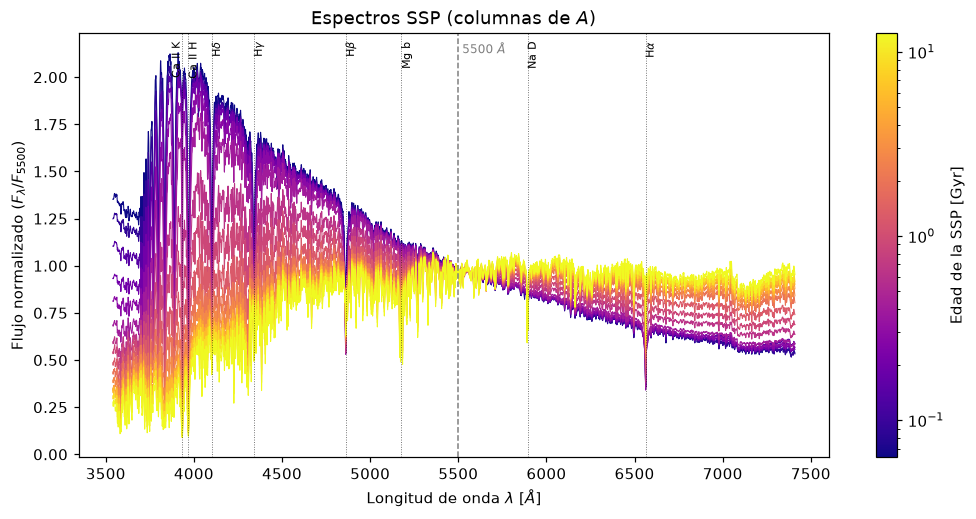

In [5]:
cmap = plt.cm.plasma
norm = LogNorm(edades.min(), edades.max())  # coloreo por edad en escala log: van de 0,06 a 12,6 Gyr

lineas = {
    "Ca II K": 3933.7,
    "Ca II H": 3968.5,
    "H$\\delta$": 4101.7,
    "H$\\gamma$": 4340.5,
    "H$\\beta$": 4861.3,
    "Mg b": 5175,
    "Na D": 5893,
    "H$\\alpha$": 6562.8,
}

fig, ax = plt.subplots(figsize=(11, 5))
# Cada columna j de A es el espectro de una edad, así que grafico A[:, j] contra lambda
for j in range(A.shape[1]):
    ax.plot(lam, A[:, j], color=cmap(norm(edades[j])), linewidth=0.7)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Edad de la SSP [Gyr]")

ax.axvline(5500, color="gray", linestyle="--", linewidth=1)
ax.text(5500, 0.98, " 5500 $\\AA$", color="gray", fontsize=8, ha="left", va="top",
        transform=ax.get_xaxis_transform())
for nombre, longitud in lineas.items():
    ax.axvline(longitud, color="k", linestyle=":", linewidth=0.6, alpha=0.6)
    # Ca II K y Ca II H están a 35 Å: pongo la K a la izquierda de su línea para que no se pisen
    lado = "right" if nombre == "Ca II K" else "left"
    ax.text(longitud, 0.98, nombre, rotation=90, fontsize=7, ha=lado, va="top",
            transform=ax.get_xaxis_transform())

ax.set_xlabel("Longitud de onda $\\lambda$ [$\\AA$]")
ax.set_ylabel(r"Flujo normalizado ($F_\lambda / F_{5500}$)")
ax.set_title("Espectros SSP (columnas de $A$)")
plt.show()

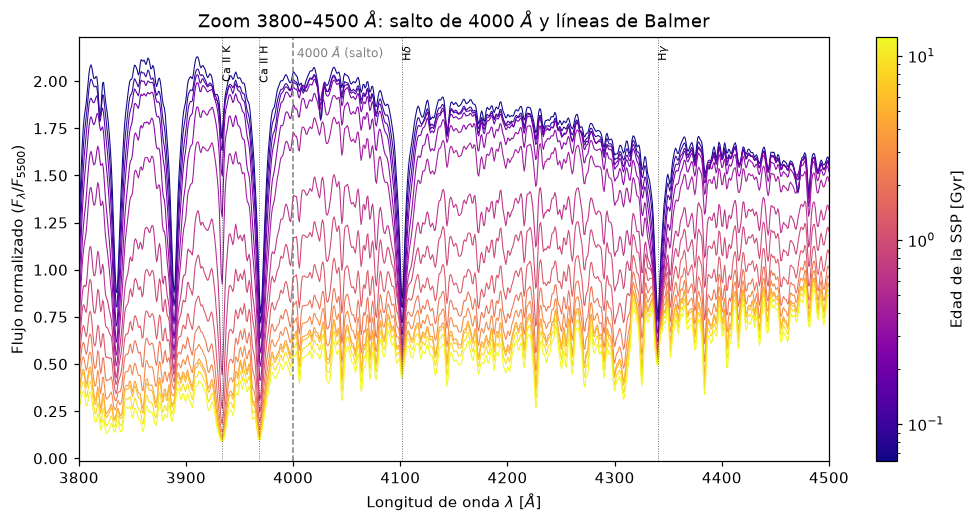

In [6]:
mascara = (lam >= 3800) & (lam <= 4500)

fig, ax = plt.subplots(figsize=(11, 5))
for j in range(A.shape[1]):
    ax.plot(lam[mascara], A[mascara, j], color=cmap(norm(edades[j])), linewidth=0.7)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Edad de la SSP [Gyr]")

ax.axvline(4000, color="gray", linestyle="--", linewidth=1)
ax.text(4000, 0.98, " 4000 $\\AA$ (salto)", color="gray", fontsize=8, ha="left", va="top",
        transform=ax.get_xaxis_transform())
for nombre, longitud in lineas.items():
    if 3800 <= longitud <= 4500:
        ax.axvline(longitud, color="k", linestyle=":", linewidth=0.6, alpha=0.6)
        ax.text(longitud, 0.98, nombre, rotation=90, fontsize=7, ha="left", va="top",
                transform=ax.get_xaxis_transform())

ax.set_xlim(3800, 4500)
ax.set_xlabel("Longitud de onda $\\lambda$ [$\\AA$]")
ax.set_ylabel(r"Flujo normalizado ($F_\lambda / F_{5500}$)")
ax.set_title("Zoom 3800–4500 $\\AA$: salto de 4000 $\\AA$ y líneas de Balmer")
plt.show()

### 3. Estructura de $A$: heatmap y correlación entre columnas

- **Heatmap.** Casi toda la variación entre columnas está en la parte azul ($\lambda$ < 5000 $\mathring{\mathrm{A}}$). En la mitad roja la matriz es casi uniforme: esas filas aportan poca información para separar edades.
- **Correlación.** Las columnas vecinas tienen una correlación de al menos 0,90 y aparecen dos bloques casi colineales: el de las jóvenes (0,06–0,4 Gyr) y el de las viejas (2–12,6 Gyr), con correlaciones de 0,98 a 1,00 entre columnas vecinas de un mismo bloque (entre los extremos de cada bloque bajan a 0,90 y 0,86). Las jóvenes y las viejas llegan a estar anticorrelacionadas (-0,67 entre 0,063 y 12,6 Gyr): normalizadas en 5500 $\mathring{\mathrm{A}}$, unas caen hacia el azul y las otras suben.
- **Implicancia.** Si las columnas son casi linealmente dependientes, $A$ tiene rango completo (15), pero está **mal condicionada**: algunas combinaciones $Ax$ con $x$ muy distintos producen espectros muy parecidos. Es esperable que perturbaciones chicas en $b$ produzcan cambios grandes en la estimación de $x$, sobre todo repartiendo peso entre edades vecinas. Esto se cuantifica con la SVD en el Ej. 3.

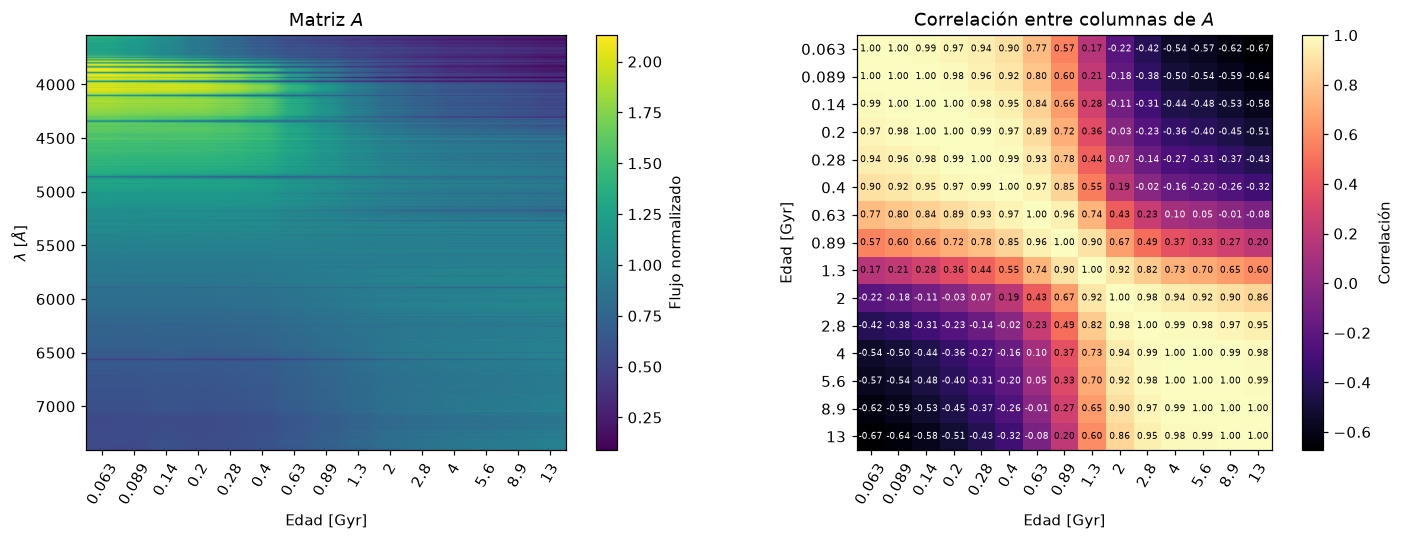

Mínima correlación entre columnas adyacentes: 0.9029
Mínima correlación global: -0.674 entre las edades 0.0631 y 12.5893 Gyr
Mínima correlación entre las columnas viejas (~2 a 12,6 Gyr): 0.861


In [7]:
etiquetas_edad = [f"{e:.2g}" for e in edades]
# Correlaciono las columnas de A: corrcoef espera las variables en las filas, por eso traspongo A
C = np.corrcoef(A.T)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

im1 = ax1.imshow(A, aspect="auto", cmap="viridis", extent=[-0.5, 14.5, lam.max(), lam.min()])
ax1.set_xticks(range(15))
ax1.set_xticklabels(etiquetas_edad, rotation=60)
ax1.set_xlabel("Edad [Gyr]")
ax1.set_ylabel("$\\lambda$ [$\\AA$]")
ax1.set_title("Matriz $A$")
cb1 = fig.colorbar(im1, ax=ax1)
cb1.set_label("Flujo normalizado")

im2 = ax2.imshow(C, cmap="magma", vmin=C.min(), vmax=1)
ax2.set_xticks(range(15))
ax2.set_yticks(range(15))
ax2.set_xticklabels(etiquetas_edad, rotation=60)
ax2.set_yticklabels(etiquetas_edad)
ax2.set_xlabel("Edad [Gyr]")
ax2.set_ylabel("Edad [Gyr]")
ax2.set_title("Correlación entre columnas de $A$")
cb2 = fig.colorbar(im2, ax=ax2)
cb2.set_label("Correlación")
# La mitad del rango de colores: abajo de eso el fondo es oscuro y el texto va en blanco, arriba en negro
umbral = (C.min() + 1) / 2
for i in range(15):
    for j in range(15):
        color_texto = "white" if C[i, j] < umbral else "black"
        ax2.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6, color=color_texto)

fig.tight_layout()
plt.show()

min_adyacente = min(C[i, i + 1] for i in range(14))
print("Mínima correlación entre columnas adyacentes:", round(float(min_adyacente), 4))
# unravel_index pasa el índice plano del mínimo a (fila, columna)
i_min, j_min = np.unravel_index(np.argmin(C), C.shape)
print("Mínima correlación global:", round(float(C[i_min, j_min]), 4),
      "entre las edades", edades[i_min], "y", edades[j_min], "Gyr")
# Las columnas viejas (de ~2 a 12,6 Gyr) son las últimas seis de A
print("Mínima correlación entre las columnas viejas (~2 a 12,6 Gyr):",
      round(float(C[9:, 9:].min()), 3))

### 4. Espectro medido $b$, espectro ideal y ruido

Definimos el ruido como $e = b - b_{ideal}$ y su nivel como $\eta = \|e\|_2$.

- $\eta \approx 0{,}115$, que en relativo es $\|e\|_2/\|b_{ideal}\|_2 \approx 0{,}19\,\%$. En la escala del espectro, $b$ y $b_{ideal}$ son indistinguibles a simple vista.
- Por píxel: media $\approx 0$ y desvío $\sigma \approx 1{,}75\times10^{-3}$, lo que con flujo $\sim 1$ equivale a una relación señal/ruido de ~570. Se verifica que $\eta \approx \sigma\sqrt{4300}$.
- El histograma se ajusta bien a una normal con la misma media y desvío. El desvío es el mismo en ambas mitades del rango de $\lambda$ (**homocedástico**) y la autocorrelación es $\approx$ 0 para todo rezago $k \ge 1$ (**ruido blanco**). Es consistente con ruido gaussiano i.i.d. agregado píxel a píxel.
- $\eta$ va a ser la referencia de los ejercicios siguientes: un ajuste con residuo mucho menor que $\eta$ estaría ajustando ruido. En el Ej. 5 es la cota de "espectros indistinguibles".

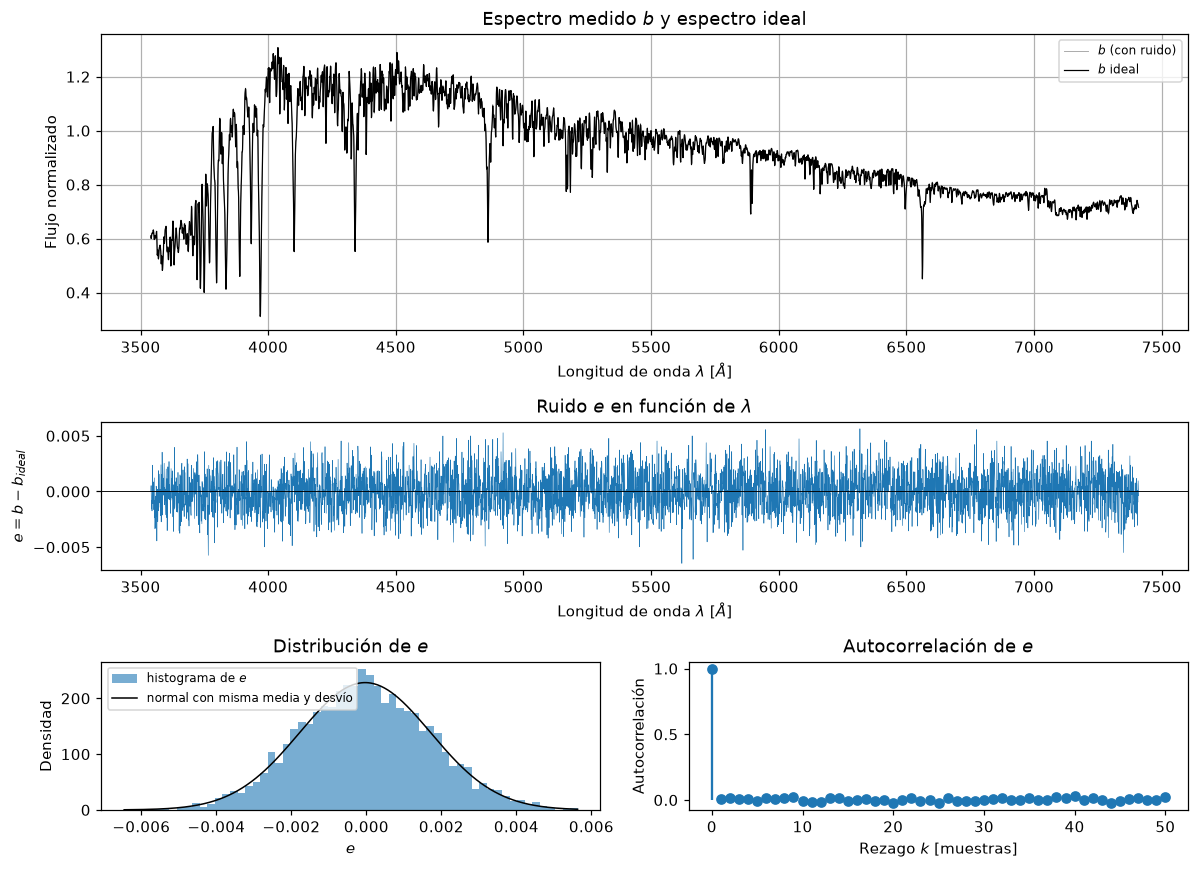

eta = ||b - b_ideal||_2 = 0.1146594955771805
eta / ||b_ideal||_2 = 0.0018787289452316719
media de e = -3.270072706976866e-05
desvío estándar de e = 0.0017482351083536072
sigma * sqrt(n) (n = cantidad de píxeles) = 0.11463944249055226
1 / sigma (relación señal/ruido, con el flujo normalizado a ~1) = 572.0054443602529
desvío estándar de e, primera mitad de lambda = 0.0017410570545361064
desvío estándar de e, segunda mitad de lambda = 0.0017549149917279589
autocorrelación de rezago 1 = 0.009365317719607826
máximo de |autocorrelación| para k >= 1 = 0.03220571320969858


In [8]:
e = b - b_ideal
# Calculo la norma del ruido, eta = ||b - b_ideal||_2 (por default norm ya calcula la l2)
eta = np.linalg.norm(e)
m = e.mean()
s = e.std()

fig, axd = plt.subplot_mosaic(
    [["s", "s"], ["e", "e"], ["h", "ac"]],
    figsize=(11, 8),
    height_ratios=[2, 1, 1],
)

ax = axd["s"]
ax.plot(lam, b, color="gray", alpha=0.7, linewidth=0.6, label="$b$ (con ruido)")
ax.plot(lam, b_ideal, color="k", linewidth=0.8, label="$b$ ideal")
ax.set_xlabel("Longitud de onda $\\lambda$ [$\\AA$]")
ax.set_ylabel("Flujo normalizado")
ax.set_title("Espectro medido $b$ y espectro ideal")
ax.legend(fontsize=8)
ax.grid()

ax = axd["e"]
ax.plot(lam, e, linewidth=0.4)
ax.axhline(0, color="k", linewidth=0.6)
ax.set_xlabel("Longitud de onda $\\lambda$ [$\\AA$]")
ax.set_ylabel("$e = b - b_{ideal}$")
ax.set_title("Ruido $e$ en función de $\\lambda$")

ax = axd["h"]
ax.hist(e, bins=60, density=True, alpha=0.6, label="histograma de $e$")
xs = np.linspace(e.min(), e.max(), 400)
pdf = np.exp(-0.5 * ((xs - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
ax.plot(xs, pdf, color="k", linewidth=1, label="normal con misma media y desvío")
ax.set_xlabel("$e$")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de $e$")
ax.legend(fontsize=8)

ax = axd["ac"]
K = 50  # miro 50 rezagos: si el ruido es blanco, pasado k = 1 la autocorrelación ya es solo ruido de estimación
# r_k = sum (e_t - m)(e_{t+k} - m) / sum (e_t - m)^2, normalizada por la varianza total
den = np.dot(e - m, e - m)
ac = np.empty(K + 1)
for k in range(K + 1):
    ac[k] = np.dot(e[:len(e) - k] - m, e[k:] - m) / den
ax.stem(np.arange(K + 1), ac, basefmt=" ")
ax.set_xlabel("Rezago $k$ [muestras]")
ax.set_ylabel("Autocorrelación")
ax.set_title("Autocorrelación de $e$")

fig.tight_layout()
plt.show()

mitad = len(e) // 2
print("eta = ||b - b_ideal||_2 =", eta)
print("eta / ||b_ideal||_2 =", eta / np.linalg.norm(b_ideal))
print("media de e =", m)
print("desvío estándar de e =", s)
print("sigma * sqrt(n) (n = cantidad de píxeles) =", s * np.sqrt(len(e)))
print("1 / sigma (relación señal/ruido, con el flujo normalizado a ~1) =", 1 / s)
print("desvío estándar de e, primera mitad de lambda =", e[:mitad].std())
print("desvío estándar de e, segunda mitad de lambda =", e[mitad:].std())
print("autocorrelación de rezago 1 =", ac[1])
print("máximo de |autocorrelación| para k >= 1 =", np.abs(ac[1:]).max())

### 5. Composición real $x_{real}$

- $x_{real}$ es una distribución de proporciones: todas positivas y con $\sum_j x_j = 1$. Es unimodal en $\log t$, con el máximo (0,10) entre 0,9 y 2 Gyr, y colas de 0,03–0,05 en los extremos. Ninguna población es despreciable.
- $\|Ax_{real} - b_{ideal}\|_2 \approx 1{,}1\times10^{-8}$ (relativo $\approx 2\times10^{-10}$, compatible con el redondeo de los CSV). Es decir, **$b_{ideal}$ se generó exactamente como $A x_{real}$**: el modelo lineal es exacto y todo el desajuste viene del ruido.
- $\|Ax_{real} - b\|_2 = \eta$: la composición verdadera deja un residuo del tamaño exacto del ruido. Que un método encuentre un $x$ con residuo algo menor que $\eta$ no significa que esté más cerca de $x_{real}$. Ese es el punto central del Ej. 2.

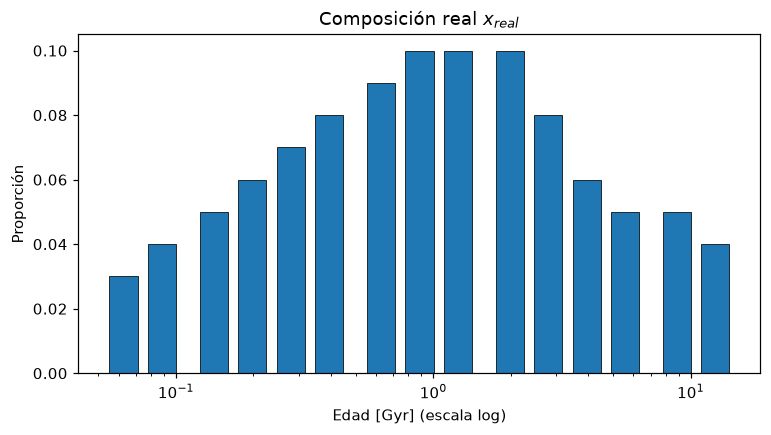

máximo de x_real = 0.1 a la edad 0.8913 Gyr
x_real en las puntas (primera y última edad) = [0.03 0.04]
Suma de x_real: 1.0
||A x_real - b_ideal||_2 = 1.0926747054199864e-08
||A x_real - b_ideal||_2 / ||b_ideal||_2 = 1.790379057976228e-10
||A x_real - b||_2 = 0.11465949561228878
eta = ||b - b_ideal||_2 = 0.1146594955771805


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ancho = edades * 0.25  # el ancho es proporcional a la edad: el eje es log y así las barras se ven parejas
ax.bar(edades, x_real, width=ancho, color="C0", edgecolor="k", linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("Edad [Gyr] (escala log)")
ax.set_ylabel("Proporción")
ax.set_title("Composición real $x_{real}$")
plt.show()

i_max = int(np.argmax(x_real))
print("máximo de x_real =", x_real[i_max], "a la edad", edades[i_max], "Gyr")
print("x_real en las puntas (primera y última edad) =", x_real[[0, -1]])
print("Suma de x_real:", x_real.sum())
error_abs = np.linalg.norm(A @ x_real - b_ideal)
print("||A x_real - b_ideal||_2 =", error_abs)
print("||A x_real - b_ideal||_2 / ||b_ideal||_2 =", error_abs / np.linalg.norm(b_ideal))
print("||A x_real - b||_2 =", np.linalg.norm(A @ x_real - b))
print("eta = ||b - b_ideal||_2 =", eta)

### Conclusiones del ejercicio 1

1. $A \in \mathbb{R}^{4300\times 15}$: cada columna es un espectro SSP normalizado en 5500 $\mathring{\mathrm{A}}$ y cada fila es una longitud de onda. Al ser $m \gg n$, el sistema $Ax \approx b$ es sobredeterminado y se resuelve por cuadrados mínimos.
2. Los espectros varían de forma suave con la edad. Las columnas vecinas están fuertemente correlacionadas ($\geq$ 0,90) y las de edades viejas vecinas son casi colineales. Por eso $A$ tiene rango completo pero se espera que esté **mal condicionada**.
3. El ruido es gaussiano, blanco y homocedástico, de nivel $\eta = \|b - b_{ideal}\|_2 \approx 0{,}115$ ($\approx$ 0,19 % de la señal).
4. $b_{ideal} = A x_{real}$ de forma exacta, así que la dificultad para recuperar $x_{real}$ viene solo de la combinación ruido + mal condicionamiento. Eso es lo que estudian los Ej. 2 a 5.

## Ejercicio 2 — Cuadrados mínimos

In [10]:
e = b - b_ideal
# eta es la norma del ruido: ||b - b_ideal||_2
eta = np.linalg.norm(e)
m, n = A.shape

print("Forma de A:", A.shape, "| m =", m, "| n =", n)
print("eta = ||b - b_ideal||_2 =", eta)

Forma de A: (4300, 15) | m = 4300 | n = 15
eta = ||b - b_ideal||_2 = 0.1146594955771805


### 1. Planteo

Como $A \in \mathbb{R}^{4300\times15}$ tiene muchas más filas que columnas, el sistema $Ax=b$ es **sobredeterminado** y, con ruido, no tiene solución exacta. Se busca entonces

$$x_{LS} = \arg\min_{x\in\mathbb{R}^{15}} \|Ax-b\|_2^2 .$$

Si $A$ tiene rango completo de columnas ($\operatorname{rg}A = 15$), el mínimo es único y cumple las **ecuaciones normales** $A^\top A\,x = A^\top b$. Geométricamente, $Ax_{LS}$ es la proyección ortogonal de $b$ sobre $\operatorname{Col}(A)$, y el residuo $r = b - Ax_{LS}$ es ortogonal a ese subespacio ($A^\top r = 0$).

No se imponen las restricciones físicas $x\ge0$ y $\mathbf 1^\top x = 1$: se resuelve el problema lineal sin restricciones y después se verifica si las cumple.

### 2. Resolución numérica

Se resuelve de tres maneras para comparar su estabilidad:

- **`np.linalg.lstsq`** (basado en la SVD, vía LAPACK).
- **QR reducida:** $A = QR$, con $Q\in\mathbb{R}^{4300\times15}$ de columnas ortonormales y $R$ triangular superior. Como $\|Ax-b\|_2^2 = \|Rx - Q^\top b\|_2^2 + \|(I-QQ^\top)b\|_2^2$, basta resolver $Rx = Q^\top b$ por sustitución hacia atrás.
- **Ecuaciones normales:** $A^\top A\,x = A^\top b$.

**Resultados.**

- $A$ tiene rango numérico 15 y $\kappa_2(A) \approx 6{,}1\times10^{3}$, en tanto que $\kappa_2(A^\top A) = \kappa_2(A)^2 \approx 3{,}7\times10^{7}$. Formar $A^\top A$ **eleva al cuadrado el condicionamiento**.
- QR coincide con `lstsq` a precisión de máquina (diferencia relativa $\sim10^{-12}$). Las ecuaciones normales pierden unos 3 dígitos más ($\sim10^{-9}$), consistente con $\kappa^2\varepsilon_{maq} \approx 3{,}7\times10^{7}\cdot2{,}2\times10^{-16} \approx 10^{-8}$.
- Acá esa pérdida no cambia nada en la práctica: el error que introduce el ruido de los datos es muchísimo mayor. Igual, QR o SVD son la opción correcta, y con un $A$ peor condicionado las ecuaciones normales sí fallarían.
- Se verifica $\|A^\top r\| \sim 10^{-12}$: el residuo es ortogonal a las columnas de $A$, como predice la teoría.

In [11]:
# rcond=None para que lstsq use el corte por default de numpy
x_ls, _, rank, _ = np.linalg.lstsq(A, b, rcond=None)
print("Rango numérico de A (lstsq):", rank)

# QR reducida: Q (4300 x 15) con columnas ortonormales, R (15 x 15) triangular superior
Q, R = np.linalg.qr(A)
# Resuelvo R x = Q^T b; R es triangular superior, así que esto equivale a una sustitución
# hacia atrás (acá uso solve de numpy en vez de escribirla a mano)
x_qr = np.linalg.solve(R, Q.T @ b)

# Ecuaciones normales: (A^T A) x = A^T b
x_ne = np.linalg.solve(A.T @ A, A.T @ b)

print("cond(A) =", np.linalg.cond(A))
print("cond(A^T A) =", np.linalg.cond(A.T @ A))
print("cond(A)^2 =", np.linalg.cond(A) ** 2)
print("||x_QR - x_LS|| / ||x_LS|| =", np.linalg.norm(x_qr - x_ls) / np.linalg.norm(x_ls))
print("||x_NE - x_LS|| / ||x_LS|| =", np.linalg.norm(x_ne - x_ls) / np.linalg.norm(x_ls))
print("||A^T (b - A x_LS)|| =", np.linalg.norm(A.T @ (b - A @ x_ls)))

Rango numérico de A (lstsq): 15
cond(A) = 6065.839028354757
cond(A^T A) = 36794403.11425216
cond(A)^2 = 36794403.11791178
||x_QR - x_LS|| / ||x_LS|| = 3.601778571373313e-13
||x_NE - x_LS|| / ||x_LS|| = 2.6578698760159982e-09
||A^T (b - A x_LS)|| = 1.182764268342261e-12


### 3. Métricas

Se incluye $x_{real}$ como columna de referencia: es lo mejor que se podría lograr conociendo la respuesta.

- **El ajuste en el espacio de los datos es excelente:** $R^2 = 0{,}9999$, residuo relativo de $0{,}19\,\%$ y RMS del residuo $\approx 1{,}74\times10^{-3}$, igual al $\sigma$ del ruido.
- **El residuo de $x_{LS}$ es *menor* que el de $x_{real}$** ($\|r\| = 0{,}9976\,\eta$). No es un mejor ajuste: cuadrados mínimos, por construcción, minimiza el residuo y **absorbe parte del ruido** en la solución. La parte del ruido que cae en $\operatorname{Col}(A)$ ($Pe$, con $P$ el proyector) se interpreta como señal: $\|r\|^2 = \|(I-P)e\|^2 = \eta^2 - \|Pe\|^2$.
- **Reconstrucción contra el ideal:** $\|Ax_{LS} - b_{ideal}\|_2 \approx 0{,}0079 \ll \eta \approx 0{,}115$. El espectro reconstruido está ~15 veces más cerca de $b_{ideal}$ que el propio $b$, porque la proyección sobre un subespacio de dimensión 15 descarta casi todo el ruido. El valor esperado es $\|Pe\| \approx \sigma\sqrt{n} = 1{,}75\times10^{-3}\sqrt{15} \approx 0{,}0068$, consistente.
- **Pero en el espacio de los coeficientes el error es grande:** $\|x_{LS}-x_{real}\|/\|x_{real}\| \approx 17{,}6\,\%$, cuando el ruido relativo en $b$ es $0{,}19\,\%$. Es decir, el error relativo se amplifica unas **90 veces**, dentro de la cota $\kappa_2(A) \approx 6000$.
- **Restricciones físicas:** $\sum x_{LS} = 0{,}99999$ (se cumple casi exacto, por la fila normalizada en 5500 $\mathring{\mathrm{A}}$ vista en el Ej. 1) y no hay componentes negativas con este $b$.

In [12]:
pd.set_option("display.float_format", "{:.6g}".format)


def metricas(x):
    r_x = A @ x - b
    nr = np.linalg.norm(r_x)
    nb = np.linalg.norm(b)
    return {
        "||Ax - b||_2": nr,
        "||Ax - b||_2 / eta": nr / eta,
        "||Ax - b|| / ||b||": nr / nb,
        "RMS del residuo ||Ax - b|| / sqrt(m)": nr / np.sqrt(m),
        "R^2 = 1 - ||Ax - b||^2 / ||b - mean(b)||^2": 1 - nr ** 2 / np.linalg.norm(b - b.mean()) ** 2,
        "||Ax - b_ideal||_2": np.linalg.norm(A @ x - b_ideal),
        "||x - x_real|| / ||x_real||": np.linalg.norm(x - x_real) / np.linalg.norm(x_real),
        "max|x - x_real|": np.max(np.abs(x - x_real)),
        "sum x": x.sum(),
        "componentes negativas": int(np.sum(x < 0)),
    }


tabla_metricas = pd.DataFrame({
    "x_LS": metricas(x_ls),
    "x_real (referencia)": metricas(x_real),
})

# ||P e|| = ||Ax_LS - b_ideal|| es la parte del ruido que cae en Col(A); su valor esperado es sigma*sqrt(n)
print("||P e|| =", np.linalg.norm(A @ x_ls - b_ideal), "| sigma*sqrt(n) =", e.std() * np.sqrt(n))

# Cuánto se amplifica el error relativo: (||x_LS - x_real|| / ||x_real||) / (||e|| / ||b_ideal||)
print("amplificación del error relativo =",
      (np.linalg.norm(x_ls - x_real) / np.linalg.norm(x_real)) / (eta / np.linalg.norm(b_ideal)))

comp = pd.DataFrame({
    "edad [Gyr]": edades,
    "x_real": x_real,
    "x_LS": x_ls,
    "x_LS - x_real": x_ls - x_real,
    "error rel. (x_LS - x_real)/x_real": (x_ls - x_real) / x_real,
})

print("Por componente:")
print(comp.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
print()
print("Métricas globales:")
tabla_metricas

||P e|| = 0.007868131848958567 | sigma*sqrt(n) = 0.00677088545990864
amplificación del error relativo = 93.55802725897608
Por componente:
 edad [Gyr]  x_real      x_LS  x_LS - x_real  error rel. (x_LS - x_real)/x_real
     0.0631    0.03 0.0316539     0.00165392                          0.0551308
     0.0891    0.04 0.0405785    0.000578527                          0.0144632
     0.1413    0.05  0.043345    -0.00665502                            -0.1331
     0.1995    0.06 0.0622342      0.0022342                          0.0372367
     0.2818    0.07 0.0706112    0.000611193                         0.00873132
     0.3981    0.08 0.0850761     0.00507607                          0.0634509
      0.631    0.09 0.0834078    -0.00659221                         -0.0732468
     0.8913     0.1  0.103303     0.00330264                          0.0330264
     1.2589     0.1  0.088648      -0.011352                           -0.11352
     1.9953     0.1  0.115798      0.0157984                  

,x_LS,x_real (referencia)
||Ax - b||_2,0.114389,0.114659
||Ax - b||_2 / eta,0.997643,1
||Ax - b|| / ||b||,0.00187436,0.00187879
RMS del residuo ||Ax - b|| / sqrt(m),0.00174442,0.00174854
R^2 = 1 - ||Ax - b||^2 / ||b - mean(b)||^2,0.999902,0.999902
||Ax - b_ideal||_2,0.00786813,1.09267e-08
||x - x_real|| / ||x_real||,0.17577,0
max|x - x_real|,0.0278394,0
sum x,0.999986,1
componentes negativas,0,0


### 4. Coeficientes estimados vs. composición real

- En las **poblaciones jóvenes** ($\leq$ 0,4 Gyr), $x_{LS}$ sigue de cerca a $x_{real}$: errores absolutos $\leq$ 0,007 y relativos de pocos por ciento (salvo 0,14 Gyr, con un 13 %).
- En las **poblaciones de edad intermedia y viejas** ($\geq$ 1,3 Gyr) los errores crecen mucho: -46 % en 4 Gyr, +51 % en 8,9 Gyr, +18 % en 2,8 Gyr.
- Los errores tienden a **compensarse, con signos opuestos entre edades cercanas** (2 y 2,8 Gyr de más, 4 Gyr de menos; 8,9 Gyr de más, 5,6 y 12,6 Gyr de menos). Cuadrados mínimos **redistribuye peso entre columnas casi colineales**: subestimar una edad y sobreestimar la vecina cambia muy poco $Ax$. Esto conecta con el bloque de correlaciones $\approx$ 1 entre las SSP viejas vecinas del Ej. 1.
- El máximo de la distribución en ~1–2 Gyr se conserva, pero aparece un pico espurio en 8,9 Gyr y los valores individuales de las edades viejas no son confiables.

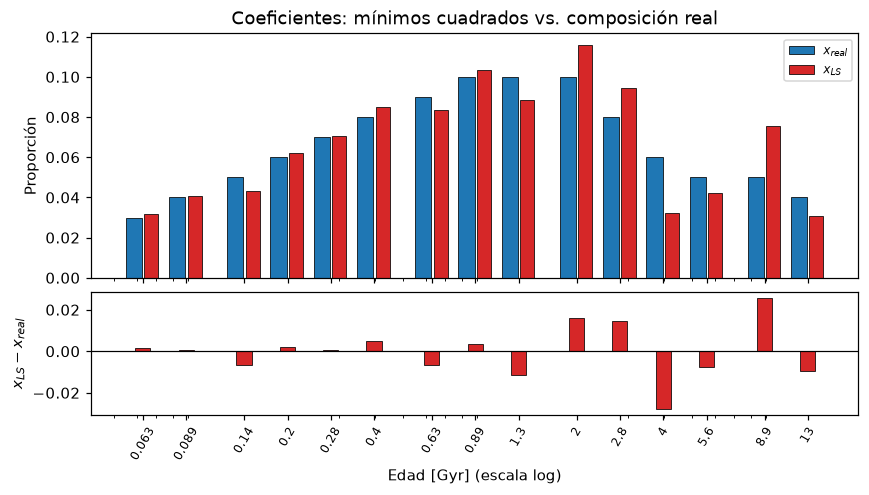

In [13]:
fig, (ax, ax_d) = plt.subplots(
    2, 1, figsize=(9, 4.5), sharex=True,
    gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08},
)
for a in (ax, ax_d):
    a.set_xscale("log")

# Corro las barras multiplicando (el eje es log) y el ancho va proporcional a la edad,
# para que se vea parejo en escala log
ancho = edades * 0.12
ax.bar(edades * 10 ** (-0.03), x_real, width=ancho, color="C0", edgecolor="k",
       linewidth=0.5, label="$x_{real}$")
ax.bar(edades * 10 ** (+0.03), x_ls, width=ancho, color="C3", edgecolor="k",
       linewidth=0.5, label="$x_{LS}$")
ax.set_ylabel("Proporción")
ax.set_title("Coeficientes: mínimos cuadrados vs. composición real")
ax.legend(fontsize=8)

ax_d.bar(edades, x_ls - x_real, width=ancho, color="C3", edgecolor="k", linewidth=0.5)
ax_d.axhline(0, color="k", linewidth=0.8)
ax_d.set_xlabel("Edad [Gyr] (escala log)")
ax_d.set_ylabel(r"$x_{LS} - x_{real}$")
ax_d.set_xticks(edades)
ax_d.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=8)
ax_d.xaxis.set_minor_formatter(NullFormatter())

plt.show()

### 5. Espectro reconstruido

- A la escala del espectro completo, y aun en el zoom de 3800–4400 $\mathring{\mathrm{A}}$ donde están las features más marcadas, $Ax_{LS}$, $b$ y $Ax_{real}$ son **indistinguibles**.
- El residuo $r$ prácticamente coincide con el ruido verdadero: $\operatorname{corr}(r,e) = 0{,}998$ y $\operatorname{std}(r) = 1{,}744\times10^{-3}$ frente a $\operatorname{std}(e) = 1{,}748\times10^{-3}$. Es gaussiano, sin estructura en $\lambda$ y sin autocorrelación (rezago 1: 0,005).
- Es el diagnóstico de un **buen ajuste del modelo**: no queda señal sin explicar en el residuo. Pero esto **no dice nada** sobre si $x$ es correcto. Los mismos $b$ y residuo son compatibles con un $x$ que tiene un 17,6 % de error.

**Conclusión de esta sección:** evaluar la solución solo por el residuo o por la calidad visual del espectro reconstruido es engañoso cuando $A$ está mal condicionada.

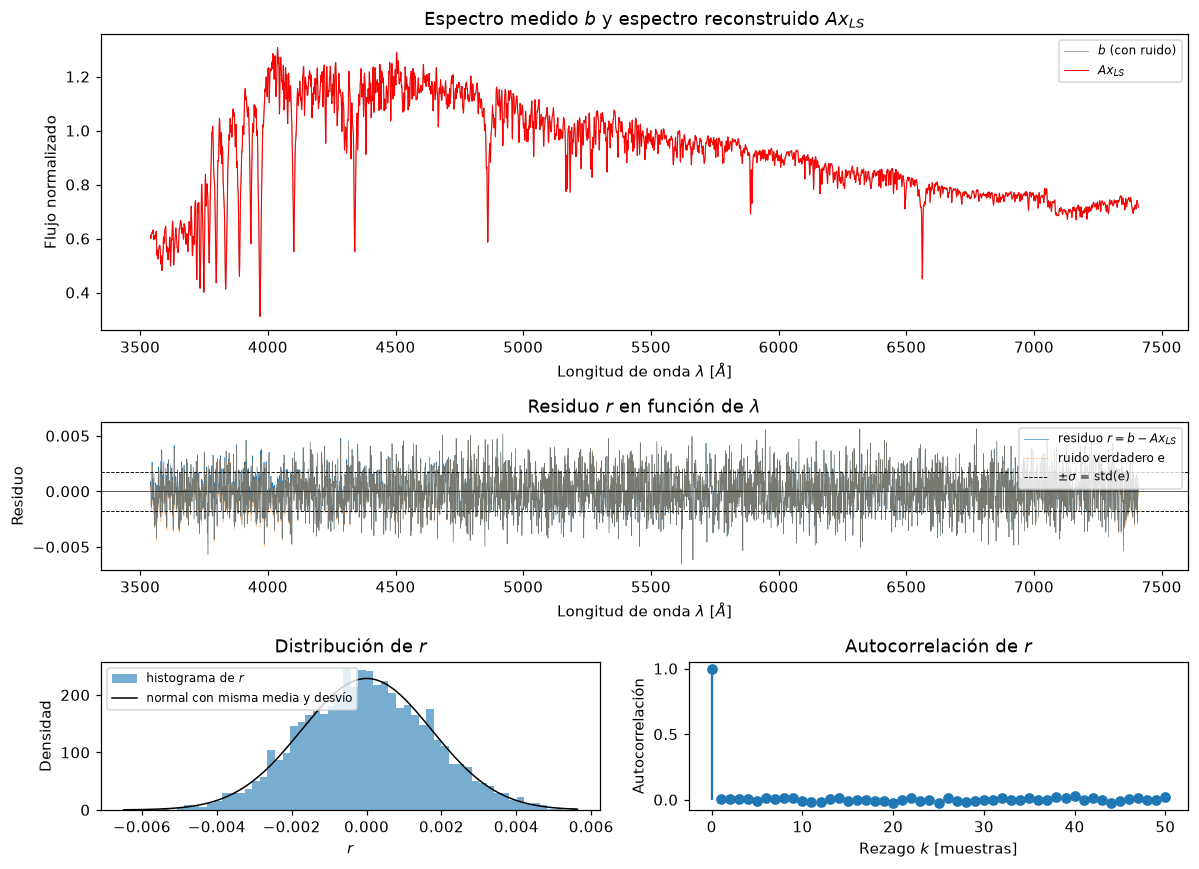

||r||_2 = 0.11438921469687814
||e||_2 = 0.1146594955771805
corr(r, e) = 0.9978314812723063
std(r) = 0.0017444186857118996
std(e) = 0.0017482351083536072
autocorrelación de r de rezago 1 = 0.004602261532549742


In [14]:
r = b - A @ x_ls
ajuste = A @ x_ls
sigma_e = e.std()


def autocorrelacion(v, K=50):
    mu = v.mean()
    den = np.dot(v - mu, v - mu)
    ac = np.empty(K + 1)
    # ac_k = sum (v_t - mu)(v_{t+k} - mu) / sum (v_t - mu)^2, con los n-k pares que se solapan
    for k in range(K + 1):
        ac[k] = np.dot(v[:len(v) - k] - mu, v[k:] - mu) / den
    return ac


ac_r = autocorrelacion(r)
mr, sr = r.mean(), r.std()

fig, axd = plt.subplot_mosaic(
    [["s", "s"], ["r", "r"], ["h", "ac"]],
    figsize=(11, 8),
    height_ratios=[2, 1, 1],
)

ax = axd["s"]
ax.plot(lam, b, color="gray", alpha=0.7, linewidth=0.6, label="$b$ (con ruido)")
ax.plot(lam, ajuste, color="red", linewidth=0.7, label="$A x_{LS}$")
ax.set_xlabel("Longitud de onda $\\lambda$ [$\\AA$]")
ax.set_ylabel("Flujo normalizado")
ax.set_title("Espectro medido $b$ y espectro reconstruido $A x_{LS}$")
ax.legend(fontsize=8)

ax = axd["r"]
ax.plot(lam, r, linewidth=0.4, color="C0", label="residuo $r = b - A x_{LS}$")
ax.plot(lam, e, linewidth=0.4, color="C1", alpha=0.4, label="ruido verdadero e")
ax.axhline(sigma_e, color="k", linestyle="--", linewidth=0.6, label=r"$\pm\sigma$ = std(e)")
ax.axhline(-sigma_e, color="k", linestyle="--", linewidth=0.6)
ax.axhline(0, color="k", linewidth=0.4)
ax.set_xlabel("Longitud de onda $\\lambda$ [$\\AA$]")
ax.set_ylabel("Residuo")
ax.set_title("Residuo $r$ en función de $\\lambda$")
ax.legend(fontsize=8, loc="upper right")

ax = axd["h"]
ax.hist(r, bins=60, density=True, alpha=0.6, label="histograma de $r$")
xs = np.linspace(r.min(), r.max(), 400)
pdf = np.exp(-0.5 * ((xs - mr) / sr) ** 2) / (sr * np.sqrt(2 * np.pi))
ax.plot(xs, pdf, color="k", linewidth=1, label="normal con misma media y desvío")
ax.set_xlabel("$r$")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de $r$")
ax.legend(fontsize=8)

ax = axd["ac"]
ax.stem(np.arange(len(ac_r)), ac_r, basefmt=" ")
ax.set_xlabel("Rezago $k$ [muestras]")
ax.set_ylabel("Autocorrelación")
ax.set_title("Autocorrelación de $r$")

fig.tight_layout()
plt.show()

print("||r||_2 =", np.linalg.norm(r))
print("||e||_2 =", np.linalg.norm(e))
print("corr(r, e) =", np.corrcoef(r, e)[0, 1])
print("std(r) =", r.std())
print("std(e) =", e.std())
print("autocorrelación de r de rezago 1 =", ac_r[1])

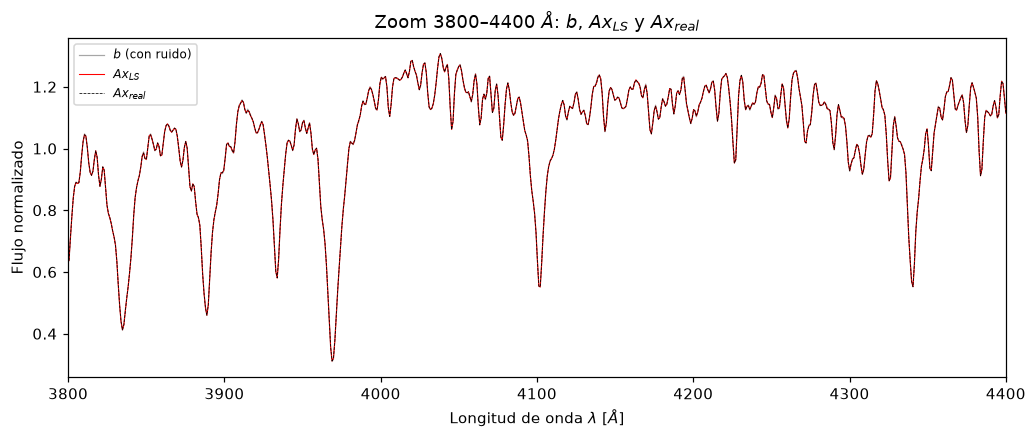

In [15]:
Ax_real = A @ x_real
mascara = (lam >= 3800) & (lam <= 4400)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(lam[mascara], b[mascara], color="gray", alpha=0.7, linewidth=0.8,
        label="$b$ (con ruido)")
ax.plot(lam[mascara], ajuste[mascara], color="red", linewidth=0.7, label="$A x_{LS}$")
ax.plot(lam[mascara], Ax_real[mascara], color="k", linewidth=0.5, linestyle="--",
        label="$A x_{real}$")
ax.set_xlim(3800, 4400)
ax.set_xlabel("Longitud de onda $\\lambda$ [$\\AA$]")
ax.set_ylabel("Flujo normalizado")
ax.set_title("Zoom 3800–4400 $\\AA$: $b$, $A x_{LS}$ y $A x_{real}$")
ax.legend(fontsize=8)

plt.show()

### 6. Sensibilidad al ruido

**(a) Sin ruido.** Con $b_{ideal}$, cuadrados mínimos recupera $x_{real}$ con un error relativo de $2\times10^{-8}$, del orden del redondeo de los CSV amplificado unas 100 veces por el mal condicionamiento, muy por debajo de la cota que da $\kappa(A)$. El método no tiene sesgo: **todo el error viene del ruido**.

**(b) Con ruido: simulación Monte Carlo.** Se generaron 500 espectros $b_k = b_{ideal} + e_k$, con $e_k \sim \mathcal N(0,\sigma^2 I)$ y el mismo $\sigma$ del ruido dado, y se resolvió cuadrados mínimos en cada uno. Como $x_{LS} - x_{real} = A^{+}e$, la teoría predice $\operatorname{Cov}(x_{LS}) = \sigma^2 (A^\top A)^{-1} = \sigma^2 V\Sigma^{-2}V^\top$: las direcciones $v_i$ con $\sigma_i$ chico son las que más se amplifican.

- **Error relativo en $x$:** media del 22 % y desvío del 8 %. El 17,6 % obtenido con el $b$ dado cae en el **percentil 30**: no fue un caso de mala suerte, es lo típico.
- **Positividad:** en el **10 %** de las realizaciones aparece al menos una proporción **negativa**, que no tiene sentido físico.

**(c) Dispersión por componente.** El coeficiente de variación $\operatorname{std}/x_{real}$ es de 9–14 % entre 0,14 y 2 Gyr, pero sube al **31–59 %** entre 2,8 y 8,9 Gyr. Coincide con el bloque de SSP viejas casi colineales del Ej. 1.

**(d) Correlación entre estimaciones.** Las estimaciones de edades vecinas están casi siempre **anticorrelacionadas**. En el par 0,063–0,089 Gyr (columnas con correlación $\approx$ 1,00 en el Ej. 1) llega a $-0{,}91$: el ruido hace que el método "pase" peso de una a la otra manteniendo casi constante su suma, que es lo que el espectro sí determina.

In [16]:
# (a) LS sobre el espectro sin ruido
x_id = np.linalg.lstsq(A, b_ideal, rcond=None)[0]
print("(a) ||x_id - x_real|| / ||x_real|| (LS sobre b_ideal) =",
      np.linalg.norm(x_id - x_real) / np.linalg.norm(x_real))

(a) ||x_id - x_real|| / ||x_real|| (LS sobre b_ideal) = 1.945939296528739e-08


In [17]:
# (b) Monte Carlo: nuevas realizaciones del ruido con el mismo sigma
# Repito el experimento: b_k = b_ideal + e_k con e_k ~ N(0, sigma^2 I), y resuelvo cuadrados
# mínimos en cada b_k. Así separo el error que viene del ruido del que vendría del método.
rng = np.random.default_rng(0)  # semilla fija para que la simulación salga siempre igual
sigma = e.std()
N = 500
X = np.empty((N, n))
normas_res = np.empty(N)
for k in range(N):
    bk = b_ideal + rng.normal(0, sigma, m)  # espectro nuevo, mismo sigma del ruido dado
    X[k] = np.linalg.lstsq(A, bk, rcond=None)[0]
    normas_res[k] = np.linalg.norm(bk - A @ X[k])

err_rel_mc = np.linalg.norm(X - x_real, axis=1) / np.linalg.norm(x_real)
err_rel_b = np.linalg.norm(x_ls - x_real) / np.linalg.norm(x_real)

print("Error relativo en x sobre las realizaciones: media =", err_rel_mc.mean(),
      "| desvío =", err_rel_mc.std())
print("Fracción de realizaciones con al menos una componente negativa =",
      np.mean((X < 0).any(axis=1)))
print("Desvío por componente de x_k:", np.round(X.std(axis=0), 4))
print("Coeficiente de variación por componente (desvío / x_real):",
      np.round(X.std(axis=0) / x_real, 2))
print("Error relativo de x_LS con el b dado =", err_rel_b)
# El percentil es la fracción de realizaciones con error <= el de x_LS con el b dado:
# si da ~30 %, el 17,6 % de nuestro b es un caso típico y no mala suerte
print("Percentil del error de x_LS con el b dado dentro de la distribución MC:",
      100 * np.mean(err_rel_mc <= err_rel_b))
print("||r_k|| en MC: media =", normas_res.mean(), "| ||e|| =", np.linalg.norm(e))

Error relativo en x sobre las realizaciones: media = 0.22472138008037415 | desvío = 0.08281537968738746
Fracción de realizaciones con al menos una componente negativa = 0.1
Desvío por componente de x_k: [0.006  0.0081 0.0069 0.0063 0.0066 0.01   0.0118 0.0137 0.0114 0.0131
 0.0252 0.0352 0.028  0.0227 0.0118]
Coeficiente de variación por componente (desvío / x_real): [0.2  0.2  0.14 0.11 0.09 0.13 0.13 0.14 0.11 0.13 0.31 0.59 0.56 0.45
 0.3 ]
Error relativo de x_LS con el b dado = 0.17577017387021215
Percentil del error de x_LS con el b dado dentro de la distribución MC: 30.0
||r_k|| en MC: media = 0.11441469910881719 | ||e|| = 0.1146594955771805


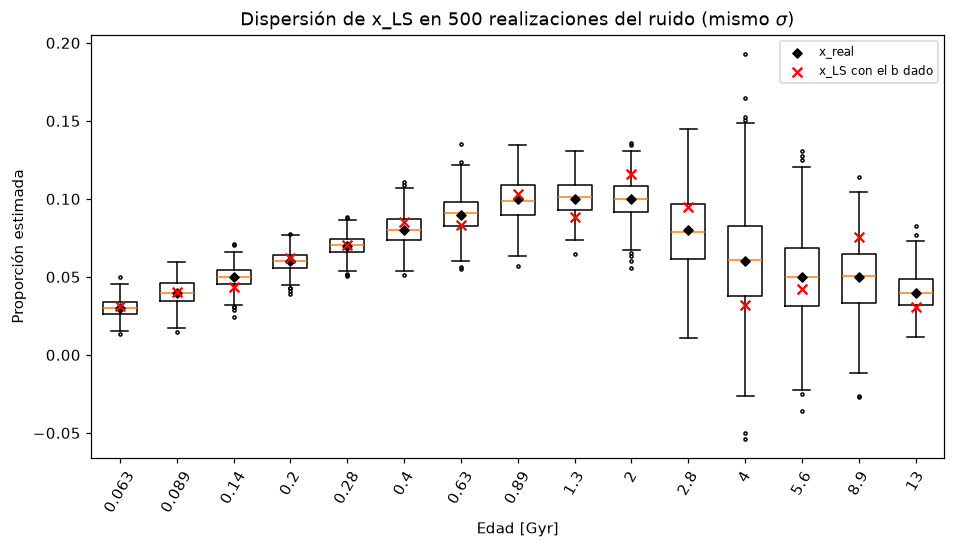

In [18]:
# (c) Boxplot de las estimaciones por componente
# Cada caja es la distribución de x_k en las N realizaciones; la comparo con x_real y x_LS
etiquetas_edad = [f"{ed:.2g}" for ed in edades]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(X, positions=np.arange(n), widths=0.6, flierprops={"markersize": 2})
ax.scatter(np.arange(n), x_real, color="k", marker="D", s=18, zorder=3, label="x_real")
ax.scatter(np.arange(n), x_ls, color="red", marker="x", s=40, zorder=4,
           label="x_LS con el b dado")
ax.set_xticks(np.arange(n))
ax.set_xticklabels(etiquetas_edad, rotation=60)
ax.set_ylabel("Proporción estimada")
ax.set_xlabel("Edad [Gyr]")
ax.set_title(f"Dispersión de x_LS en {N} realizaciones del ruido (mismo $\\sigma$)")
ax.legend(fontsize=8)
plt.show()

Par adyacente con correlación más negativa entre estimaciones: edades 0.063 y 0.089 Gyr
corr(x_i, x_j) = -0.9117879458110453
Correlaciones de pares adyacentes (i, i+1): [-0.91, -0.28, -0.7, 0.15, -0.63, -0.66, -0.79, -0.74, -0.25, -0.68, -0.6, -0.67, -0.28, -0.82]


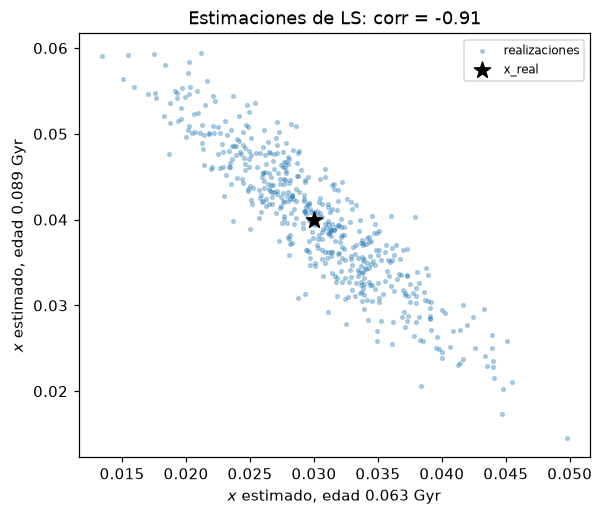

In [19]:
# (d) Correlación entre estimaciones de componentes adyacentes
# corrcoef de las columnas de X: Cx[i, j] = corr(x_i, x_j) entre realizaciones
Cx = np.corrcoef(X.T)
# np.diag(Cx, 1) es la diagonal de arriba, o sea corr(x_i, x_{i+1}); busco el par más negativo
i_par = int(np.argmin(np.diag(Cx, 1)))
j_par = i_par + 1
print("Par adyacente con correlación más negativa entre estimaciones: edades",
      etiquetas_edad[i_par], "y", etiquetas_edad[j_par], "Gyr")
print("corr(x_i, x_j) =", Cx[i_par, j_par])
print("Correlaciones de pares adyacentes (i, i+1):",
      [round(float(Cx[i, i + 1]), 2) for i in range(n - 1)])

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X[:, i_par], X[:, j_par], s=6, alpha=0.3, label="realizaciones")
ax.scatter(x_real[i_par], x_real[j_par], color="k", marker="*", s=120, zorder=3,
           label="x_real")
ax.set_xlabel(f"$x$ estimado, edad {etiquetas_edad[i_par]} Gyr")
ax.set_ylabel(f"$x$ estimado, edad {etiquetas_edad[j_par]} Gyr")
ax.set_title(f"Estimaciones de LS: corr = {Cx[i_par, j_par]:.2f}")
ax.legend(fontsize=8)
plt.show()

### Conclusiones del ejercicio 2

1. El problema de cuadrados mínimos tiene solución única ($\operatorname{rg}A = 15$). Se resolvió en forma estable con QR o SVD. Las ecuaciones normales funcionan, pero pierden dígitos porque $\kappa(A^\top A) = \kappa(A)^2 \approx 3{,}7\times10^7$.
2. **En el espacio de los datos el ajuste es casi perfecto:** residuo $\approx$ $\eta$, $R^2 = 0{,}9999$, residuo indistinguible del ruido, y espectro reconstruido incluso más cercano a $b_{ideal}$ que el propio $b$.
3. **En el espacio de los coeficientes el error es del 17,6 %** (típicamente 22 % $\pm$ 8 %). Un ruido del 0,19 % se amplifica ~90 veces por el mal condicionamiento de $A$ ($\kappa \approx 6\times10^3$), con errores concentrados en las edades viejas y de signo opuesto entre edades cercanas. En un 10 % de los casos aparecen proporciones negativas.
4. **Un residuo chico no garantiza un $x$ correcto.** Cuadrados mínimos ajusta también parte del ruido; por eso su residuo es *menor* que el de la solución verdadera. Esto motiva analizar la estructura de $A$ con la SVD (Ej. 3) y regularizar (Ej. 4).

## Ejercicio 3 — SVD, pseudoinversa y truncamiento

In [20]:
# eta es la norma del ruido: ||b - b_ideal||_2
eta = np.linalg.norm(b - b_ideal)

### 1. Descomposición en valores singulares

Se calcula la SVD reducida $A = U\Sigma V^\top$, con $U\in\mathbb{R}^{4300\times15}$ de columnas ortonormales, $\Sigma = \operatorname{diag}(\sigma_1,\dots,\sigma_{15})$ con $\sigma_1\ge\dots\ge\sigma_{15}>0$, y $V\in\mathbb{R}^{15\times15}$ ortogonal. Se verifica que $U\Sigma V^\top$ reconstruye $A$ y que $U$ y $V$ son ortonormales a precisión de máquina.

- Los 15 valores singulares son positivos: $A$ tiene **rango completo**.
- Caen **casi cuatro órdenes de magnitud**, de $\sigma_1\approx241$ a $\sigma_{15}\approx0{,}040$, y $\kappa_2(A) = \sigma_1/\sigma_{15}\approx6066$. Es el mismo valor que en el Ej. 2.
- Hay un **codo claro después de $\sigma_4$**: los cuatro primeros concentran casi toda la "energía" de $A$, y de $\sigma_5$ en adelante la caída es lenta (de 0,66 a 0,04). Las columnas de $A$ están cerca de un subespacio de dimensión ~4, consistente con la alta correlación entre SSP vista en el Ej. 1.

Forma de A: (4300, 15)
Forma de U: (4300, 15) | forma de s: (15,) | forma de Vt: (15, 15)
Valores singulares:
  sigma_ 1 = 2.4118e+02
  sigma_ 2 = 5.5180e+01
  sigma_ 3 = 8.2031e+00
  sigma_ 4 = 3.0729e+00
  sigma_ 5 = 6.5858e-01
  sigma_ 6 = 4.2879e-01
  sigma_ 7 = 3.2382e-01
  sigma_ 8 = 2.5067e-01
  sigma_ 9 = 2.0894e-01
  sigma_10 = 1.6066e-01
  sigma_11 = 1.3095e-01
  sigma_12 = 9.1740e-02
  sigma_13 = 6.7652e-02
  sigma_14 = 5.9931e-02
  sigma_15 = 3.9761e-02
s[0] / s[-1] = 6065.839028354761
||A - U diag(s) Vt|| / ||A|| = 9.711877385629466e-16
||U.T @ U - I|| = 4.089217193113227e-15
||Vt @ Vt.T - I|| = 4.163988009115086e-15


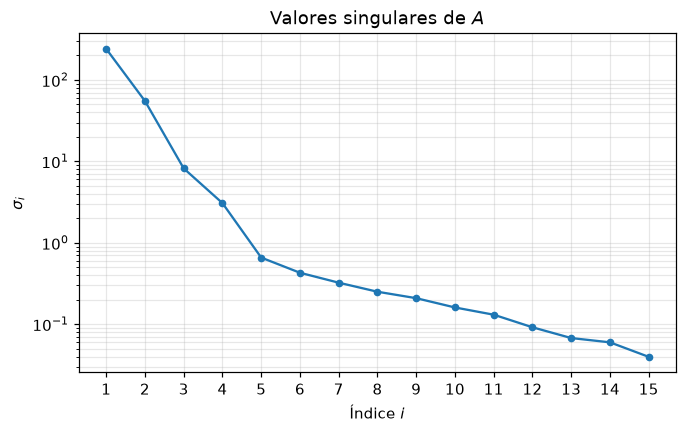

In [21]:
# Uso full_matrices=False para quedarme con la SVD reducida: U es 4300x15 y Vt es 15x15
U, s, Vt = np.linalg.svd(A, full_matrices=False)
n = A.shape[1]

print("Forma de A:", A.shape)
print("Forma de U:", U.shape, "| forma de s:", s.shape, "| forma de Vt:", Vt.shape)
print("Valores singulares:")
for i, sv in enumerate(s, start=1):
    print(f"  sigma_{i:2d} = {sv:.4e}")
print("s[0] / s[-1] =", s[0] / s[-1])
# np.diag(s) arma la matriz Sigma con los valores singulares en la diagonal
print("||A - U diag(s) Vt|| / ||A|| =", np.linalg.norm(A - U @ np.diag(s) @ Vt) / np.linalg.norm(A))
print("||U.T @ U - I|| =", np.linalg.norm(U.T @ U - np.eye(n)))
print("||Vt @ Vt.T - I|| =", np.linalg.norm(Vt @ Vt.T - np.eye(n)))

indices = np.arange(1, n + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(indices, s, "o-", markersize=4)
ax.set_xlabel(r"Índice $i$")
ax.set_ylabel(r"$\sigma_i$")
ax.set_xticks(indices)
ax.grid(True, which="both", alpha=0.3)
ax.set_title(r"Valores singulares de $A$")
plt.show()

### 2. Pseudoinversa y solución

La pseudoinversa de Moore–Penrose se construye a partir de la SVD como

$$A^{+} = V\Sigma^{-1}U^\top, \qquad x_{+} = A^{+}b = \sum_{i=1}^{15}\frac{u_i^\top b}{\sigma_i}\,v_i .$$

**Resultado:** $x_{+}$ coincide con $x_{LS}$ del Ej. 2 a precisión de máquina (diferencia relativa $\sim10^{-12}$). Tiene el mismo error relativo (17,6 %) y el mismo residuo.

**Justificación.** Como $\operatorname{rg}A = 15$, $A^\top A = V\Sigma^2V^\top$ es invertible y

$$(A^\top A)^{-1}A^\top = V\Sigma^{-2}V^\top\,V\Sigma U^\top = V\Sigma^{-1}U^\top = A^{+}.$$

Es decir, $A^{+}b$ es exactamente la solución de las ecuaciones normales, que es la única solución de cuadrados mínimos. Se verifica numéricamente: $A^{+} = (A^\top A)^{-1}A^\top$, $A^{+}A = I_{15}$ y la construcción coincide con `np.linalg.pinv`. Cambia el algoritmo, no el problema: con rango completo, la pseudoinversa no aporta nada nuevo **mientras se usen todas las componentes**.

La expresión en suma explica por qué esa solución es sensible al ruido. Con $b = b_{ideal} + e$, cada término trae una parte $\frac{u_i^\top e}{\sigma_i}v_i$. Las proyecciones $u_i^\top e$ del ruido blanco tienen todas un tamaño similar ($\sim\sigma_{ruido}\approx2\times10^{-3}$), pero se dividen por $\sigma_i$, que llega a $0{,}04$. Los términos con $\sigma_i$ chico **amplifican el ruido** hasta ~25 veces.

In [22]:
# A+ = V Sigma^-1 U^T, con Sigma^-1 = diag(1/s)
A_pinv = Vt.T @ np.diag(1 / s) @ U.T
x_pinv = A_pinv @ b
# rcond=None para que lstsq use el corte por default de numpy
x_ls = np.linalg.lstsq(A, b, rcond=None)[0]
A_pinv_np = np.linalg.pinv(A)

print("||x_pinv - x_LS|| / ||x_LS|| =", np.linalg.norm(x_pinv - x_ls) / np.linalg.norm(x_ls))
print("||A+ - pinv(A)|| / ||pinv(A)|| =",
      np.linalg.norm(A_pinv - A_pinv_np) / np.linalg.norm(A_pinv_np))
print("||A+ - (A^T A)^-1 A^T|| / ||A+|| =",
      np.linalg.norm(A_pinv - np.linalg.solve(A.T @ A, A.T)) / np.linalg.norm(A_pinv))
print("||A+ A - I|| =", np.linalg.norm(A_pinv @ A - np.eye(n)))
print("||x_pinv - x_real|| / ||x_real|| =", np.linalg.norm(x_pinv - x_real) / np.linalg.norm(x_real))
print("||A x_pinv - b|| =", np.linalg.norm(A @ x_pinv - b))

# Ruido e = b - b_ideal y sus proyecciones u_i^T e sobre la base de U
e = b - b_ideal
print("sigma_ruido = ||e||_2 / sqrt(len(e)) =", np.linalg.norm(e) / np.sqrt(len(e)))
print("u_i^T e =", np.round(U.T @ e, 4))
print("factor de amplificación máximo 1/sigma_15 =", 1 / s[-1])

||x_pinv - x_LS|| / ||x_LS|| = 9.745009785175257e-13
||A+ - pinv(A)|| / ||pinv(A)|| = 1.0607854499822027e-16
||A+ - (A^T A)^-1 A^T|| / ||A+|| = 3.5284696173009853e-10
||A+ A - I|| = 4.098711045115109e-13
||x_pinv - x_real|| / ||x_real|| = 0.17577017387032065
||A x_pinv - b|| = 0.11438921469687797
sigma_ruido = ||e||_2 / sqrt(len(e)) = 0.0017485409150577635
u_i^T e = [ 0.0023 -0.0037 -0.0026 -0.0024 -0.0017 -0.0033  0.0003 -0.0023 -0.0011
 -0.0012  0.0004 -0.0017 -0.0019  0.0011 -0.0009]
factor de amplificación máximo 1/sigma_15 = 25.150417939374847


### 3. Aproximación de rango $k$

La aproximación de rango $k$ conserva las primeras $k$ componentes de rango uno,

$$A_k = \sum_{i=1}^{k}\sigma_i\,u_i v_i^\top, \qquad x_k = A_k^{+}b = \sum_{i=1}^{k}\frac{u_i^\top b}{\sigma_i}\,v_i ,$$

que es la **SVD truncada** (TSVD). Por el teorema de Eckart–Young, $A_k$ es la mejor aproximación de rango $k$ en norma 2, con $\|A-A_k\|_2 = \sigma_{k+1}$. Se verifica numéricamente para $k=5$, y también que la fórmula de $x_k$ coincide con `pinv(A_k) b`.

Truncar equivale a **descartar los términos con $\sigma_i$ chico**, que son justamente los que amplifican el ruido.

In [23]:
X = np.empty((n, n))  # fila k-1 = x_k
filas = []
for k in range(1, n + 1):
    # x_k = suma_{i=1}^{k} (u_i^T b / sigma_i) v_i, término a término como en la teórica
    x_k = np.zeros(n)
    for i in range(k):
        x_k += (U[:, i] @ b) / s[i] * Vt[i]   # sumo el término i: (u_i^T b / sigma_i) v_i
    X[k - 1] = x_k
    r_k = np.linalg.norm(A @ x_k - b)
    filas.append({
        "k": k,
        # s[k] es sigma_{k+1}, porque numpy indexa desde 0; si k = n el término se anula
        "||A-A_k||_2": s[k] if k < n else 0.0,
        "||x_k - x_real||/||x_real||": np.linalg.norm(x_k - x_real) / np.linalg.norm(x_real),
        "||A x_k - b||_2": r_k,
        "||A x_k - b||_2/eta": r_k / eta,
        "||x_k||_2": np.linalg.norm(x_k),
        "sum x_k": x_k.sum(),
        "# componentes negativas": int(np.sum(x_k < 0)),
    })

# Verificación para k = 5: x_k = pinv(A_k) b y ||A - A_k||_2 = s[k]
k0 = 5
A_5 = U[:, :k0] @ np.diag(s[:k0]) @ Vt[:k0]
x_5_pinv = np.linalg.pinv(A_5, rcond=1e-12) @ b
print("k = 5: ||x_5 - pinv(A_5, rcond=1e-12) b|| / ||pinv(A_5, rcond=1e-12) b|| =",
      np.linalg.norm(X[k0 - 1] - x_5_pinv) / np.linalg.norm(x_5_pinv))
print("k = 5: ||A - A_5||_2 =", np.linalg.norm(A - A_5, 2), "| s[5] (sigma_6) =", s[k0])

pd.set_option("display.float_format", "{:.6g}".format)
tabla_k = pd.DataFrame(filas)
errores_x = tabla_k["||x_k - x_real||/||x_real||"]
k_min = int(tabla_k.loc[errores_x.idxmin(), "k"])
print(f"k con error relativo mínimo en x: k = {k_min}, error = {errores_x.min():.6g}")

# Menor k cuyo residuo alcanza el nivel de ruido: ||A x_k - b|| / eta <= 1
res_rel_k = tabla_k["||A x_k - b||_2/eta"]
k_eta = int(tabla_k.loc[res_rel_k <= 1, "k"].iloc[0])
print(f"menor k con ||A x_k - b||_2/eta <= 1: k = {k_eta}")
tabla_k

k = 5: ||x_5 - pinv(A_5, rcond=1e-12) b|| / ||pinv(A_5, rcond=1e-12) b|| = 3.2145709290186955e-14
k = 5: ||A - A_5||_2 = 0.42878517994905063 | s[5] (sigma_6) = 0.42878517994905013
k con error relativo mínimo en x: k = 11, error = 0.0646497
menor k con ||A x_k - b||_2/eta <= 1: k = 5


,k,||A-A_k||_2,||x_k - x_real||/||x_real||,||A x_k - b||_2,||A x_k - b||_2/eta,||x_k||_2,sum x_k,# componentes negativas
0,1,55.18,0.379128,3.0128,26.2761,0.25273,0.970003,0
1,2,8.20308,0.324225,0.532534,4.64448,0.25838,0.997838,0
2,3,3.07289,0.240243,0.207599,1.81057,0.265206,0.998863,0
3,4,0.658583,0.13048,0.11661,1.01701,0.271032,0.999897,0
4,5,0.428785,0.0720088,0.114647,0.999895,0.272956,1.00005,0
5,6,0.323825,0.076849,0.114571,0.99923,0.27313,1.00008,0
6,7,0.250674,0.0691177,0.11454,0.998961,0.273253,1.00006,0
7,8,0.208943,0.07663,0.114526,0.998837,0.273348,1.00004,0
8,9,0.160656,0.0665123,0.114472,0.998367,0.273865,1.00001,0
9,10,0.130948,0.064846,0.114442,0.998106,0.274348,1.00003,0


### 4. Cómo varía la solución con $k$

- **Residuo:** $\|Ax_k-b\|$ decrece de forma monótona con $k$ (más componentes $\Rightarrow$ más grados de libertad). Cae muy rápido hasta $k=4$ y desde $k\approx4$–5 queda **plano en $\approx\eta$**: las componentes 5 a 15 casi no mejoran el ajuste del espectro.
- **Error en $x$:** **no** es monótono.
  - Para $k$ chico ($k\le4$) domina el **error de truncamiento**: faltan componentes que sí contienen señal y la solución sale demasiado "suave" (con $k=2$, casi plana).
  - Para $k$ grande ($k\ge12$) domina el **error por ruido amplificado** ($u_i^\top e/\sigma_i$ con $\sigma_i$ chico) y la solución se deteriora hacia el 17,6 % de cuadrados mínimos.
  - Entre $k=5$ y $k=11$, el error se mantiene en torno al **6,5–7,7 %**. El mínimo es de 6,5 % en $k=11$, menos de la mitad que con cuadrados mínimos.
- Las barras lo muestran: con $k=2$ la forma no se recupera, con $k=6$ y $k=9$ la composición sigue de cerca a $x_{real}$ en todo el rango de edades, con $k=12$ aparecen oscilaciones entre edades vecinas de 0,6 a 2 Gyr, y con $k=15$ reaparecen las oscilaciones entre edades viejas (2, 2,8, 4 y 8,9 Gyr) que se vieron en el Ej. 2.
- Salvo para $k=1$ ($\sum x_k=0{,}97$), la suma queda en $\approx1$ y no hay componentes negativas en ningún caso.

**Elección de $k$ sin conocer $x_{real}$.** En un problema real no se puede calcular el error en $x$. Un criterio razonable es tomar el menor $k$ cuyo residuo no supera el nivel de ruido, $\|Ax_k-b\|_2\le\eta$, que se lee directamente de la columna $\|Ax_k-b\|_2/\eta$ de la tabla: con $k=4$ el residuo todavía es $1{,}017\,\eta$ y con $k=5$ ya es $0{,}9999\,\eta$, así que $k=5$, en coincidencia con el codo de los valores singulares. Con $k=5$ el error es del 7,2 %, muy cerca del mínimo. El margen con que $k=5$ cumple la regla es mínimo ($0{,}9999\,\eta$ contra $\eta$), así que con otra realización del ruido o con un $\eta$ estimado podría elegirse un $k$ vecino. Pero la elección no es frágil: entre $k=5$ y $k=11$ el residuo queda plano en $\approx\eta$ y el error se mantiene entre 6,5 % y 7,7 %.

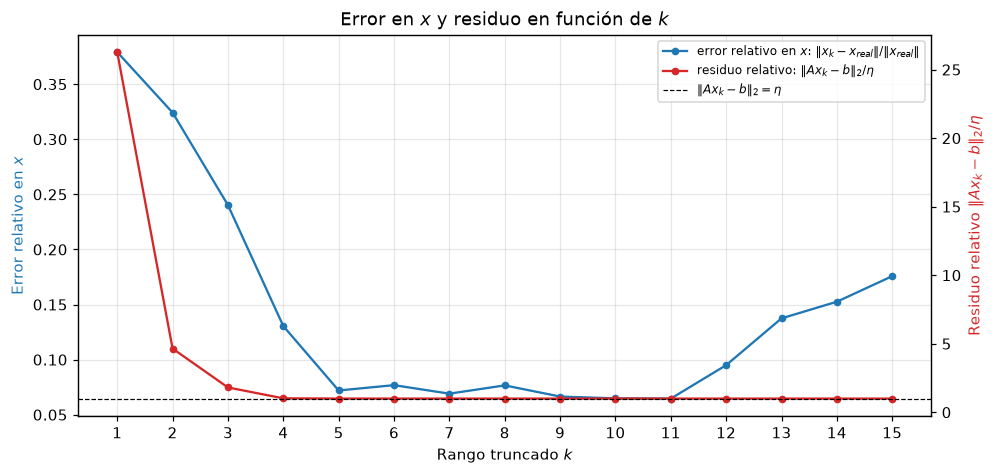

In [24]:
ks = tabla_k["k"].to_numpy()
err_x = tabla_k["||x_k - x_real||/||x_real||"].to_numpy()
res_rel = tabla_k["||A x_k - b||_2/eta"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax2 = ax.twinx()

l1, = ax.plot(ks, err_x, "o-", color="C0", markersize=4,
              label=r"error relativo en $x$: $\|x_k - x_{real}\| / \|x_{real}\|$")
l2, = ax2.plot(ks, res_rel, "o-", color="C3", markersize=4,
               label=r"residuo relativo: $\|A x_k - b\|_2 / \eta$")
l3 = ax2.axhline(1, color="k", linestyle="--", linewidth=0.8,
                 label=r"$\|A x_k - b\|_2 = \eta$")

ax.set_xlabel("Rango truncado $k$")
ax.set_ylabel("Error relativo en $x$", color="C0")
ax2.set_ylabel(r"Residuo relativo $\|A x_k - b\|_2 / \eta$", color="C3")
ax.set_xticks(ks)
ax.grid(True, alpha=0.3)
ax.set_title(r"Error en $x$ y residuo en función de $k$")
ax.legend(handles=[l1, l2, l3], loc="best", fontsize=8)

plt.show()

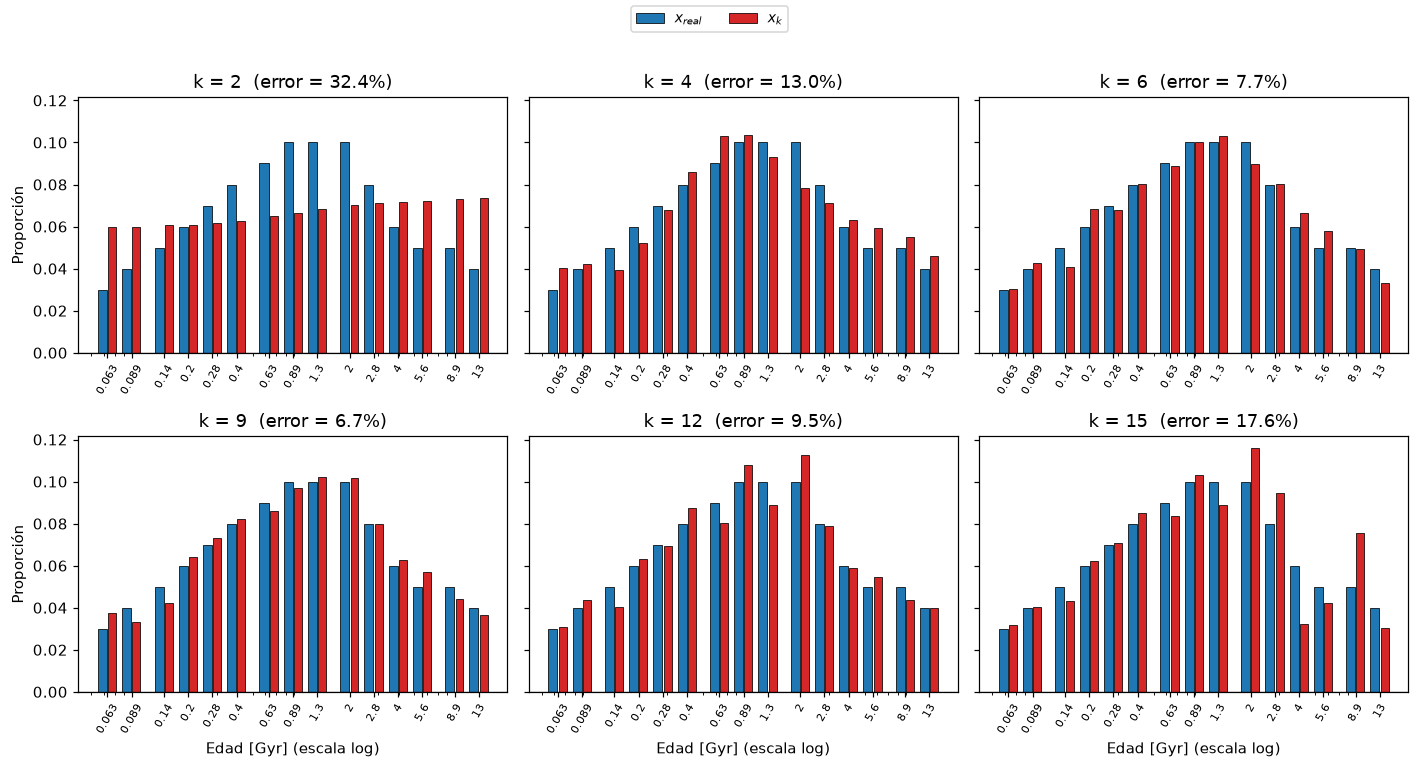

In [25]:
ks_b = [2, 4, 6, 9, 12, 15]
# Corro las barras un +/-7 % multiplicando porque el eje es log, y el ancho es
# proporcional a la edad para que se vean parejas en escala log
ancho = edades * 0.12

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, k in zip(axes.ravel(), ks_b):
    x_k = X[k - 1]
    err = np.linalg.norm(x_k - x_real) / np.linalg.norm(x_real)
    ax.set_xscale("log")
    ax.bar(edades * 10 ** (-0.03), x_real, width=ancho, color="C0", edgecolor="k",
           linewidth=0.5, label=r"$x_{real}$")
    ax.bar(edades * 10 ** (+0.03), x_k, width=ancho, color="C3", edgecolor="k",
           linewidth=0.5, label=r"$x_k$")
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"k = {k}  (error = {err:.1%})")
    ax.set_xticks(edades)
    ax.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=7)
    ax.xaxis.set_minor_formatter(NullFormatter())

for ax in axes[1]:
    ax.set_xlabel("Edad [Gyr] (escala log)")
for ax in axes[:, 0]:
    ax.set_ylabel("Proporción")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))

plt.show()

### Conclusiones del ejercicio 3

1. $A$ tiene rango completo, pero sus valores singulares caen casi cuatro órdenes de magnitud ($\kappa\approx6\times10^3$), con un codo en $\sigma_4$.
2. La pseudoinversa $A^{+} = V\Sigma^{-1}U^\top$ da **exactamente la misma solución que cuadrados mínimos**, porque con rango completo $A^{+} = (A^\top A)^{-1}A^\top$.
3. Escrita como $\sum_i (u_i^\top b/\sigma_i)\,v_i$, la solución muestra el origen del problema: los $\sigma_i$ chicos amplifican el ruido.
4. Truncar a rango $k$ (TSVD) elimina esos términos. El residuo prácticamente no cambia para $k\ge5$, pero el error en $x$ baja del 17,6 % a ~6,5–7,7 %. Hay un compromiso entre error de truncamiento ($k$ chico) y ruido amplificado ($k$ grande).
5. Elegir el menor $k$ con $\|Ax_k-b\|_2\le\eta$ ($k=5$) da un resultado casi óptimo sin usar $x_{real}$. Esto motiva la regularización de Tikhonov del Ej. 4, que en lugar de cortar las componentes las atenúa en forma gradual.

## Ejercicio 4 — Regularización de Tikhonov

In [26]:
# eta es la norma del ruido, ||b - b_ideal||_2; en un problema real no se conoce
# porque haría falta b_ideal
eta = np.linalg.norm(b - b_ideal)
print("eta / ||b|| =", eta / np.linalg.norm(b))

n = A.shape[1]

eta / ||b|| = 0.0018787889651626052


### 1. Qué es la regularización de Tikhonov

La regularización de Tikhonov reemplaza el problema de cuadrados mínimos por

$$x_\alpha = \arg\min_{x}\ \|Ax-b\|_2^2 + \alpha^2\|Lx\|_2^2 ,$$

donde el segundo término **penaliza soluciones "grandes"** (o, con otra $L$, poco suaves). El parámetro $\alpha>0$ regula el compromiso entre ajustar los datos y controlar la solución. En **orden 0** se toma $L=I$ y se penaliza $\|x\|_2$.

Derivando e igualando a cero:

$$(A^\top A + \alpha^2 I)\,x_\alpha = A^\top b .$$

La matriz $A^\top A+\alpha^2I$ es simétrica definida positiva para todo $\alpha>0$, así que la solución existe y es única aunque $A$ esté mal condicionada. Sus autovalores son $\sigma_i^2+\alpha^2$, lo que reduce el número de condición de $\sigma_1^2/\sigma_n^2$ a $(\sigma_1^2+\alpha^2)/(\sigma_n^2+\alpha^2)$. Con la SVD $A=U\Sigma V^\top$,

$$x_\alpha = \sum_{i=1}^{15} f_i\,\frac{u_i^\top b}{\sigma_i}\,v_i, \qquad f_i = \frac{\sigma_i^2}{\sigma_i^2+\alpha^2}\in(0,1).$$

Los **factores de filtro** $f_i$ valen $\approx1$ si $\sigma_i\gg\alpha$ (la componente se conserva) y $\approx\sigma_i^2/\alpha^2$ si $\sigma_i\ll\alpha$ (la componente se atenúa). Es una versión suave de la TSVD del Ej. 3, que usa $f_i\in\{0,1\}$.

**¿Conviene para este problema?** Sí. Los ejercicios anteriores mostraron que:
- $A$ tiene rango completo pero $\kappa(A)\approx6\times10^3$, con valores singulares chicos;
- en la solución de cuadrados mínimos esos $\sigma_i$ chicos amplifican el ruido (error en $x$ del 17,6 % con un ruido del 0,19 %);
- descartar esas componentes (TSVD) baja el error a ~7 % sin empeorar el residuo.

Tikhonov ataca exactamente esto, y en lugar de un corte abrupto con $k$ entero tiene un parámetro continuo $\alpha$.

### 2. Implementación

Se implementa con la fórmula de filtros sobre la SVD y se verifica contra dos formas equivalentes:

- **Ecuaciones normales regularizadas:** $(A^\top A+\alpha^2I)x = A^\top b$.
- **Sistema aumentado:** $\min_x \left\| \begin{bmatrix}A\\ \alpha I\end{bmatrix}x - \begin{bmatrix}b\\ 0\end{bmatrix}\right\|_2$, que es un problema de cuadrados mínimos común porque su función objetivo es exactamente $\|Ax-b\|^2+\alpha^2\|x\|^2$.

Las tres coinciden ($10^{-10}$ con las ecuaciones normales, que pierden algunos dígitos al formar $A^\top A$, y $10^{-13}$ con el sistema aumentado). Con $\alpha=0$ se recupera la solución de cuadrados mínimos.

In [27]:
# A = U Sigma V^T; con full_matrices=False me quedo con los 15 vectores singulares
U, s, Vt = np.linalg.svd(A, full_matrices=False)
beta = U.T @ b  # coeficientes u_i^T b

print("kappa(A) =", s[0] / s[-1])
print("sigma_15 =", s[-1], " sigma_4 =", s[3], " sigma_3 =", s[2])


def tikhonov(alpha):
    # x_alpha = sum f_i (u_i^T b / sigma_i) v_i  con  f_i = sigma_i^2 / (sigma_i^2 + alpha^2)
    f = s**2 / (s**2 + alpha**2)          # factores de filtro
    return Vt.T @ (f * beta / s)


def err_rel(x):
    # mido el error relativo en x: ||x - x_real|| / ||x_real||
    return np.linalg.norm(x - x_real) / np.linalg.norm(x_real)


def residuo(x):
    # mido qué tan bien x explica los datos: ||A x - b||_2
    return np.linalg.norm(A @ x - b)

kappa(A) = 6065.839028354761
sigma_15 = 0.03976077067230067  sigma_4 = 3.0728894087262653  sigma_3 = 8.203081794363793


In [28]:
alpha_v = 0.3
x_svd = tikhonov(alpha_v)
# ecuaciones normales regularizadas: (A^T A + alpha^2 I) x = A^T b
x_ne = np.linalg.solve(A.T @ A + alpha_v**2 * np.eye(n), A.T @ b)
# sistema aumentado [A; alpha I] x ~ [b; 0], un cuadrados mínimos común
x_aug = np.linalg.lstsq(
    np.vstack([A, alpha_v * np.eye(n)]),
    np.concatenate([b, np.zeros(n)]),
    rcond=None,  # rcond=None: uso el corte por defecto de numpy
)[0]

print(f"alpha = {alpha_v}, ecuaciones normales vs. SVD: ||x_NE - x_SVD|| / ||x_SVD|| =",
      np.linalg.norm(x_ne - x_svd) / np.linalg.norm(x_svd))
print(f"alpha = {alpha_v}, sistema aumentado vs. SVD: ||x_aug - x_SVD|| / ||x_SVD|| =",
      np.linalg.norm(x_aug - x_svd) / np.linalg.norm(x_svd))

x_ls_chk = np.linalg.lstsq(A, b, rcond=None)[0]
print("alpha = 0, tikhonov vs. lstsq: ||x_0 - x_LS|| / ||x_LS|| =",
      np.linalg.norm(tikhonov(0.0) - x_ls_chk) / np.linalg.norm(x_ls_chk))

alpha = 0.3, ecuaciones normales vs. SVD: ||x_NE - x_SVD|| / ||x_SVD|| = 1.180845293939909e-10
alpha = 0.3, sistema aumentado vs. SVD: ||x_aug - x_SVD|| / ||x_SVD|| = 1.014061019254338e-13
alpha = 0, tikhonov vs. lstsq: ||x_0 - x_LS|| / ||x_LS|| = 7.090485703298961e-13


### 3. Cómo varía $x_\alpha$ con $\alpha$

- **$\alpha$ muy chico** ($\alpha\lesssim10^{-3}$, muy por debajo de $\sigma_{15}\approx0{,}04$): todos los $f_i\approx1$ y $x_\alpha\approx x_{LS}$, con un error del 17,6 % y las mismas oscilaciones entre edades viejas vecinas.
- **$\alpha$ del orden de los $\sigma_i$ chicos** ($0{,}05\lesssim\alpha\lesssim0{,}5$): se atenúan las componentes con valores singulares chicos, que son las que traen ruido amplificado, empezando por las últimas y llegando a la componente 5 solo hacia el extremo superior del rango. El error baja hasta un **mínimo de ~4 %** cerca de $\alpha\approx0{,}18$, mientras el residuo casi no cambia ($\approx$ $\eta$).
- **$\alpha$ grande** ($\alpha\gtrsim1$): se empiezan a atenuar componentes que sí tienen señal ($\sigma_4\approx3$, $\sigma_3\approx8$). La solución se **sobresuaviza**: con $\alpha=10$ la distribución queda casi plana y se pierde la forma de $x_{real}$. El residuo crece rápido (3,3 $\eta$ en $\alpha=10$ y 81 $\eta$ en $\alpha=100$). Para $\alpha\to\infty$, $x_\alpha\approx A^\top b/\alpha^2\to0$.
- $\|x_\alpha\|_2$ decrece de forma monótona con $\alpha$ y el residuo crece de forma monótona, como corresponde a la función objetivo.
- En todo el rango, $\sum x_\alpha\approx1$ salvo para $\alpha$ muy grande, y no aparecen componentes negativas.

El comportamiento es el mismo compromiso que en la TSVD, pero continuo: **error por ruido** para $\alpha$ chico y **error por regularización (sesgo)** para $\alpha$ grande. La figura marca los $\sigma_i$ sobre el eje de $\alpha$: el mínimo del error cae justo en la zona de los valores singulares chicos.

In [29]:
alphas = np.logspace(-4, 2, 200)
X_alpha = np.array([tikhonov(a) for a in alphas])  # fila i = x_{alpha_i}
err = np.array([err_rel(x) for x in X_alpha])
res = np.array([residuo(x) for x in X_alpha])
norma = np.linalg.norm(X_alpha, axis=1)  # axis=1: una norma por fila
negativas = (X_alpha < 0).sum(axis=1)

print("||x_alpha|| decrece con alpha:", np.all(np.diff(norma) <= 0))
print("residuo crece con alpha:", np.all(np.diff(res) >= 0))
print("máximo de componentes negativas en la grilla:", negativas.max())

alphas_tabla = [1e-4, 1e-3, 1e-2, 3e-2, 0.1, 0.2, 0.3, 0.5, 1, 3, 10, 100]
pd.set_option("display.float_format", "{:.6g}".format)
filas = []
for a in alphas_tabla:
    x = tikhonov(a)
    r = residuo(x)
    filas.append({
        "alpha": a,
        "error rel x": err_rel(x),
        "residuo": r,
        "residuo/eta": r / eta,
        "||x_alpha||_2": np.linalg.norm(x),
        "sum x_alpha": x.sum(),
        "# negativas": int(np.sum(x < 0)),
    })
tabla_alpha = pd.DataFrame(filas)
tabla_alpha

||x_alpha|| decrece con alpha: True
residuo crece con alpha: True
máximo de componentes negativas en la grilla: 0


,alpha,error rel x,residuo,residuo/eta,||x_alpha||_2,sum x_alpha,# negativas
0,0.0001,0.17577,0.114389,0.997643,0.279204,0.999986,0
1,0.001,0.175714,0.114389,0.997643,0.279201,0.999986,0
2,0.01,0.1704,0.114389,0.997643,0.278925,0.999987,0
3,0.03,0.139592,0.114391,0.997657,0.277432,0.999992,0
4,0.1,0.0575892,0.114418,0.997897,0.274258,1.00001,0
5,0.2,0.0417111,0.114477,0.99841,0.273082,1.00002,0
6,0.3,0.0498541,0.11457,0.999222,0.272451,1,0
7,0.5,0.0681283,0.114918,1.00226,0.271528,0.999957,0
8,1,0.10094,0.116965,1.02011,0.269963,0.999804,0
9,3,0.160606,0.155221,1.35375,0.265189,0.999046,0


### 4. Elección de $\alpha$

En un problema real $x_{real}$ no se conoce, así que $\alpha$ no se puede elegir minimizando el error en $x$. Se usa el **principio de discrepancia de Morozov**: tomar el $\alpha$ para el cual el residuo iguala el nivel de ruido,

$$\|Ax_\alpha - b\|_2 = \eta .$$

La idea es que no tiene sentido ajustar los datos mejor que su nivel de ruido, porque eso sería ajustar el ruido. Elegir el mayor $\alpha$ compatible con los datos regulariza lo más posible sin dejar de explicar el espectro. Acá $\eta=\|b-b_{ideal}\|_2$ es conocido. En la práctica se lo estima como $\sigma_{ruido}\sqrt{m}$.

Como el residuo es una función creciente de $\alpha$, la ecuación tiene solución única. Se resolvió por **bisección** en $\log_{10}\alpha$:

- **$\alpha_d\approx0{,}37$**, con residuo $=\eta$ y **error en $x$ de 5,6 %**.
- Como referencia (con información que no se tendría), el $\alpha$ que minimiza el error es $\approx0{,}18$, con un error de 4,1 %. El criterio de discrepancia elige un $\alpha$ del mismo orden y queda a 1,5 puntos del óptimo.

Se elige $\boldsymbol{\alpha = \alpha_d \approx 0{,}37}$.

In [30]:
lo, hi = -4.0, 2.0  # log10(alpha)
# el residuo crece con alpha, así que residuo(10**lo) < eta < residuo(10**hi):
# el cruce con eta está en el intervalo y lo busco bisecando en log10(alpha)
if residuo(tikhonov(10**lo)) > eta or residuo(tikhonov(10**hi)) < eta:
    raise ValueError("El residuo no cruza eta en [1e-4, 1e2]")
for _ in range(200):
    mid = 0.5 * (lo + hi)
    # si residuo(mid) < eta todavía ajusto mejor que el ruido, así que el cruce
    # está a la derecha: muevo el extremo izquierdo
    if residuo(tikhonov(10**mid)) < eta:
        lo = mid
    else:
        hi = mid
    if hi - lo < 1e-10:
        break
alpha_d = 10 ** (0.5 * (lo + hi))

x_d = tikhonov(alpha_d)
print(f"alpha_d (discrepancia) = {alpha_d:.6g}")
print(f"  residuo/eta = {residuo(x_d) / eta:.6g}")
print(f"  error rel x = {err_rel(x_d):.6g}")
print(f"  ||x||_2 = {np.linalg.norm(x_d):.6g}")
print(f"  sum x = {x_d.sum():.6g}")
print(f"  # negativas = {int(np.sum(x_d < 0))}")

i_opt = int(np.argmin(err))
alpha_opt = alphas[i_opt]
print(f"alpha_opt (referencia, mínimo de error rel x sobre la grilla) = {alpha_opt:.6g}")
print(f"  error rel x = {err[i_opt]:.6g}")

alpha_d (discrepancia) = 0.366106
  residuo/eta = 1
  error rel x = 0.0561103
  ||x||_2 = 0.272112
  sum x = 0.99999
  # negativas = 0
alpha_opt (referencia, mínimo de error rel x sobre la grilla) = 0.180419
  error rel x = 0.0412119


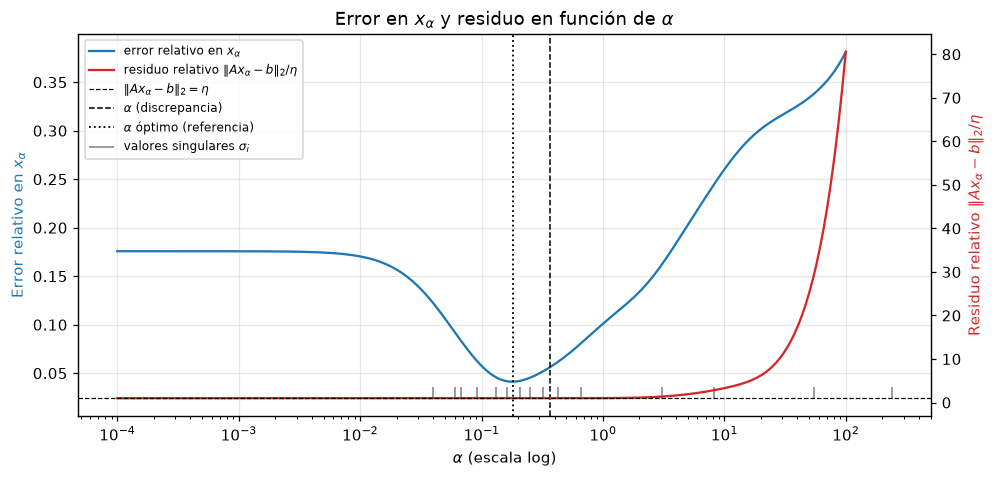

In [31]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax2 = ax.twinx()
ax.set_xscale("log")

l1, = ax.plot(alphas, err, "-", color="C0",
              label=r"error relativo en $x_\alpha$")
l2, = ax2.plot(alphas, res / eta, "-", color="C3",
               label=r"residuo relativo $\|A x_\alpha - b\|_2 / \eta$")
l3 = ax2.axhline(1, color="k", linestyle="--", linewidth=0.8,
                 label=r"$\|A x_\alpha - b\|_2 = \eta$")
l4 = ax.axvline(alpha_d, color="k", linestyle="--", linewidth=1,
                label="$\\alpha$ (discrepancia)")
l5 = ax.axvline(alpha_opt, color="k", linestyle=":", linewidth=1.2,
                label="$\\alpha$ óptimo (referencia)")
y0, y1 = ax.get_ylim()
l6 = ax.vlines(s, y0, y0 + 0.03 * (y1 - y0), color="gray", linewidth=1,
               label="valores singulares $\\sigma_i$")

ax.set_xlabel(r"$\alpha$ (escala log)")
ax.set_ylabel(r"Error relativo en $x_\alpha$", color="C0")
ax2.set_ylabel(r"Residuo relativo $\|A x_\alpha - b\|_2 / \eta$", color="C3")
ax.grid(True, alpha=0.3)
ax.set_title(r"Error en $x_\alpha$ y residuo en función de $\alpha$")
ax.legend(handles=[l1, l2, l3, l4, l5, l6], loc="best", fontsize=8)

plt.show()

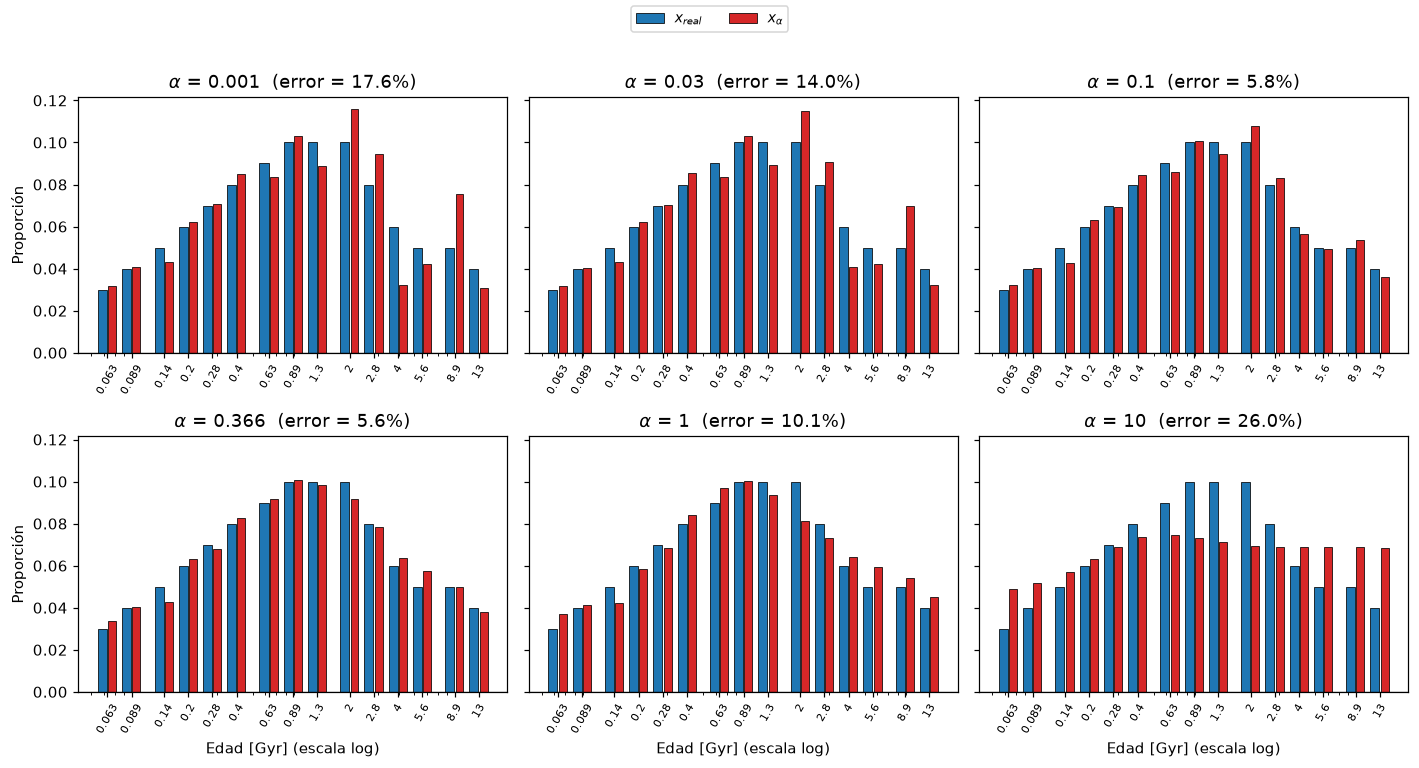

In [32]:
alphas_fig = [1e-3, 3e-2, 0.1, alpha_d, 1, 10]
ancho = edades * 0.12  # eje x log: el ancho de barra es proporcional a la edad para que se vea parejo

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, a in zip(axes.ravel(), alphas_fig):
    x_a = tikhonov(a)
    err_a = err_rel(x_a)
    ax.set_xscale("log")
    # en escala log las barras se corren multiplicando por 10**+/-0.03, no sumando
    ax.bar(edades * 10 ** (-0.03), x_real, width=ancho, color="C0", edgecolor="k",
           linewidth=0.5, label=r"$x_{real}$")
    ax.bar(edades * 10 ** (+0.03), x_a, width=ancho, color="C3", edgecolor="k",
           linewidth=0.5, label=r"$x_\alpha$")
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"$\\alpha$ = {a:.3g}  (error = {err_a:.1%})")
    ax.set_xticks(edades)
    ax.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=7)
    ax.xaxis.set_minor_formatter(NullFormatter())

for ax in axes[1]:
    ax.set_xlabel("Edad [Gyr] (escala log)")
for ax in axes[:, 0]:
    ax.set_ylabel("Proporción")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))

plt.show()

### 5. Comparación con los ejercicios anteriores

| Método | Error en $x$ | Residuo / $\eta$ |
|---|---|---|
| Cuadrados mínimos (Ej. 2) | 17,6 % | 0,998 |
| TSVD, $k=5$ (menor $k$ con residuo $\le\eta$, Ej. 3) | 7,2 % | 1,000 |
| TSVD, $k=11$ óptimo (referencia) | 6,5 % | 0,998 |
| **Tikhonov, $\alpha=0{,}37$ por discrepancia** | **5,6 %** | 1,000 |

- Los tres métodos **ajustan el espectro igual de bien**: el residuo es $\approx$ $\eta$ en todos los casos. La diferencia está solo en el espacio de los coeficientes.
- Tikhonov con $\alpha$ elegido por discrepancia da el **menor error** (5,6 %, menos de un tercio del de cuadrados mínimos) y el menor error máximo por componente (0,008 frente a 0,028). En este $b$ supera incluso a la mejor TSVD posible; con una sola realización del ruido no alcanza para afirmar que atenuar gradualmente sea mejor en general que conservar o descartar componentes enteras.
- En el gráfico de comparación, cuadrados mínimos muestra las oscilaciones en 2, 2,8, 4 y 8,9 Gyr. TSVD y Tikhonov las eliminan y siguen la forma de $x_{real}$ en todo el rango. Los errores residuales de ambos son parecidos (por ejemplo, ambos subestiman 2 Gyr y sobreestiman 4 y 5,6 Gyr): corresponden a direcciones que ningún método puede recuperar con este nivel de ruido, que es el tema del Ej. 5.

,error rel x,max|x-x_real|,residuo/eta,||x||_2,sum x,# negativas
Cuadrados mínimos (Ej. 2),0.17577,0.0278394,0.997643,0.279204,0.999986,0
TSVD k=5 (Ej. 3),0.0720088,0.0112243,0.999895,0.272956,1.00005,0
"TSVD k=11 (óptimo, referencia)",0.0646497,0.0095791,0.99808,0.274423,1.00003,0
Tikhonov alpha=0.366,0.0561103,0.008247,1,0.272112,0.99999,0


error rel x_LS / ruido relativo = 93.55503844733282


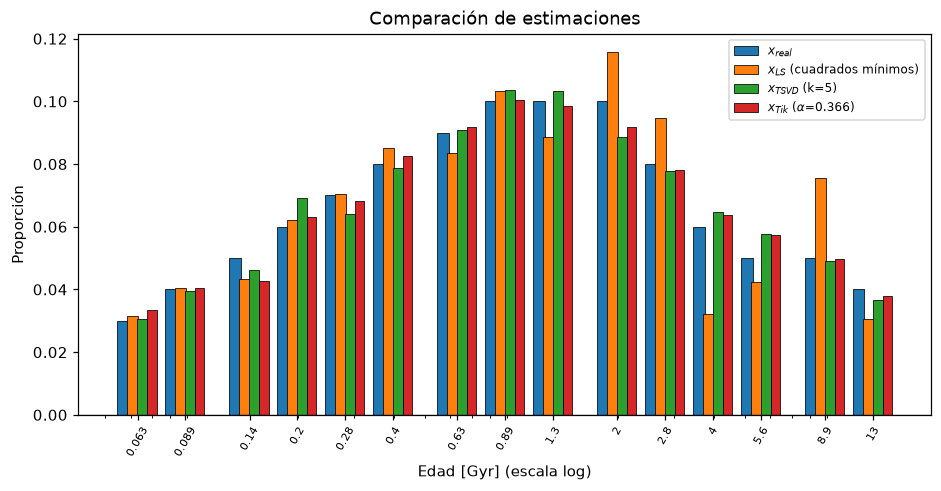

In [33]:
x_ls = np.linalg.lstsq(A, b, rcond=None)[0]
# x_k = sum_{i<=k} (u_i^T b / sigma_i) v_i = Vt[:k].T @ (beta[:k] / sigma[:k]): me quedo con las k
# primeras componentes. k=5 sale del criterio de discrepancia y k=11 del mínimo
# error (los dos del Ej. 3)
x_tsvd = Vt[:5].T @ (beta[:5] / s[:5])
x_tsvd_opt = Vt[:11].T @ (beta[:11] / s[:11])
x_tik = x_d  # ya lo calculé en la bisección


def metricas(x):
    r = residuo(x)
    return {
        "error rel x": err_rel(x),
        "max|x-x_real|": np.max(np.abs(x - x_real)),
        "residuo/eta": r / eta,
        "||x||_2": np.linalg.norm(x),
        "sum x": x.sum(),
        "# negativas": int(np.sum(x < 0)),
    }


comparacion = pd.DataFrame(
    [metricas(x_ls), metricas(x_tsvd), metricas(x_tsvd_opt), metricas(x_tik)],
    index=[
        "Cuadrados mínimos (Ej. 2)",
        "TSVD k=5 (Ej. 3)",
        "TSVD k=11 (óptimo, referencia)",
        f"Tikhonov alpha={alpha_d:.3g}",
    ],
)
display(comparacion)
print("error rel x_LS / ruido relativo =",
      err_rel(x_ls) / (eta / np.linalg.norm(b)))

# en escala log corro cada serie multiplicando por 10**+/-0.045, no sumando
series = [
    (x_real, r"$x_{real}$", "C0", 10 ** (-0.045)),
    (x_ls, r"$x_{LS}$ (cuadrados mínimos)", "C1", 10 ** (-0.015)),
    (x_tsvd, r"$x_{TSVD}$ (k=5)", "C2", 10 ** (+0.015)),
    (x_tik, f"$x_{{Tik}}$ ($\\alpha$={alpha_d:.3g})", "C3", 10 ** (+0.045)),
]
ancho = edades * 0.075  # eje x log: el ancho de barra es proporcional a la edad para que se vea parejo

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.set_xscale("log")
for x, etiqueta, color, factor in series:
    ax.bar(edades * factor, x, width=ancho, color=color, edgecolor="k",
           linewidth=0.5, label=etiqueta)
ax.axhline(0, color="k", linewidth=0.8)
ax.set_xticks(edades)
ax.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=7)
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Edad [Gyr] (escala log)")
ax.set_ylabel("Proporción")
ax.set_title("Comparación de estimaciones")
ax.legend(fontsize=8)

plt.show()

### Conclusiones del ejercicio 4

1. La regularización de Tikhonov de orden 0 agrega $\alpha^2\|x\|^2$ a la función objetivo. En términos de la SVD, multiplica cada componente por $f_i=\sigma_i^2/(\sigma_i^2+\alpha^2)$, lo que atenúa las asociadas a valores singulares chicos, que son las que amplifican el ruido.
2. Conviene para este problema: $A$ está mal condicionada ($\kappa\approx6\times10^3$) y sin regularizar el error relativo del ruido se amplifica ~90 veces (sección 1).
3. Al variar $\alpha$ aparece el compromiso entre ruido ($\alpha$ chico, $x_\alpha\to x_{LS}$) y sesgo ($\alpha$ grande, solución sobresuavizada que tiende a 0). El error es mínimo cuando $\alpha$ es del orden de los $\sigma_i$ chicos.
4. Con $\alpha\approx0{,}37$, elegido por el principio de discrepancia sin usar $x_{real}$, el error baja del 17,6 % al **5,6 %**, con el mismo residuo. Con este $b$ es el de menor error entre los métodos comparados, aunque con una sola realización del ruido no alcanza para afirmar que le gane siempre a la TSVD.

## Ejercicio 5 — Poblaciones distintas con espectros casi indistinguibles

In [34]:
pd.set_option("display.float_format", "{:.6g}".format)

e = b - b_ideal
eta = np.linalg.norm(e)  # eta = ||b - b_ideal||_2 es la norma del ruido; en un problema real no la conozco porque necesito b_ideal
sigma_ruido = e.std()    # desvío del ruido, para comparar diferencias de flujo píxel a píxel
n = A.shape[1]
uno = np.ones(n)

print("eta = ||b - b_ideal||_2 =", eta)

eta = ||b - b_ideal||_2 = 0.1146594955771805


### 1. Planteo

Se buscan dos composiciones $x^{(1)}, x^{(2)}$ en el conjunto de proporciones $\{x\in\mathbb{R}^{15}: x\ge0,\ \mathbf 1^\top x = 1\}$ que sean claramente distintas pero cuyos espectros cumplan $\|Ax^{(1)}-Ax^{(2)}\|_2<\eta$, con $\eta=\|b-b_{ideal}\|_2\approx0{,}115$ el nivel de ruido.

Se parte de una composición inicial $x_0$ (con $x_0\geq0$ y $\mathbf 1^\top x_0=1$) y se usan composiciones $x_0+\tau d$, $\tau\in\mathbb{R}$, con un **vector de redistribución** $d$, $\mathbf 1^\top d=0$:

- La suma se conserva para todo $\tau$: $\mathbf 1^\top(x_0+\tau d) = 1 + \tau\cdot0 = 1$. Solo hay que cuidar la **positividad**, que limita cuánto se puede avanzar sobre $d$.
- Si $x^{(1)} = x_0+\tau_+ d$ y $x^{(2)} = x_0-\tau_- d$, con $\tau_\pm\ge0$, entonces
$$x^{(1)}-x^{(2)} = (\tau_++\tau_-)\,d, \qquad b^{(1)}-b^{(2)} = (\tau_++\tau_-)\,Ad .$$
La diferencia en el espectro es proporcional a $\|Ad\|$. Para que las composiciones difieran mucho y los espectros poco, hace falta una **redistribución $d$ con $\|Ad\|$ lo más chico posible**:
$$\min_{\|d\|_2=1,\ \mathbf 1^\top d=0}\ \|Ad\|_2 .$$

Se toma $x_0 = x_{real}$, que es interior al conjunto (todas sus componentes son $\geq$ 0,03). Eso deja margen para moverse en ambos sentidos y permite leer el resultado como "la composición verdadera frente a alternativas".

### 2. Base ortonormal de las redistribuciones (QR)

El conjunto de redistribuciones permitidas $\{d: \mathbf 1^\top d = 0\} = \mathbf 1^\perp$ es un subespacio de dimensión 14. Para obtener una base ortonormal se calcula la **factorización QR completa** del vector $\mathbf 1\in\mathbb{R}^{15\times1}$:

$$\mathbf 1 = QR = \begin{bmatrix} q_1 & Q_2\end{bmatrix}\begin{bmatrix} r_{11}\\ 0\end{bmatrix}, \qquad Q\in\mathbb{R}^{15\times15}\ \text{ortogonal}.$$

- Como $\mathbf 1 = r_{11}q_1$, la primera columna es $q_1 = \mathbf 1/r_{11}$, con $|r_{11}| = \|\mathbf 1\|_2 = \sqrt{15}$. Se verifica $r_{11} = -\sqrt{15}$ y $q_1 = -\mathbf 1/\sqrt{15}$ (el signo depende de la convención de Householder).
- Las columnas de $Q_2\in\mathbb{R}^{15\times14}$ son ortonormales y ortogonales a $q_1$, es decir, a $\mathbf 1$: forman una **base ortonormal de $\mathbf 1^\perp$**. Se verifica que $Q^\top Q = I$ y $\mathbf 1^\top Q_2 = 0$ a precisión de máquina.

Toda redistribución se escribe entonces como $d = Q_2c$, con $c\in\mathbb{R}^{14}$, y $\|d\|_2 = \|c\|_2$ porque $Q_2$ tiene columnas ortonormales. La restricción $\mathbf 1^\top d=0$ desaparece al cambiar de variable.

In [35]:
Q, R = np.linalg.qr(uno.reshape(-1, 1), mode="complete")
# mode="complete": Q es 15x15; sus columnas 2..15 son una base ortonormal de 1^perp
q1 = Q[:, 0]
Q2 = Q[:, 1:]

print("Q.shape =", Q.shape)
print(f"R[0, 0] = {R[0, 0]:.6f} | +/-sqrt(n) = +/-{np.sqrt(n):.6f}")
print("||Q.T @ Q - I|| =", np.linalg.norm(Q.T @ Q - np.eye(n)))
print("max |uno.T @ Q2| =", np.abs(uno @ Q2).max())
print(f"q1[0] = {q1[0]:.6f} | +/-1/sqrt(n) = +/-{1 / np.sqrt(n):.6f} | max |q1 - q1[0]| = {np.abs(q1 - q1[0]).max():.3e}")

Q.shape = (15, 15)
R[0, 0] = -3.872983 | +/-sqrt(n) = +/-3.872983
||Q.T @ Q - I|| = 5.973016268314492e-16
max |uno.T @ Q2| = 3.3306690738754696e-16
q1[0] = -0.258199 | +/-1/sqrt(n) = +/-0.258199 | max |q1 - q1[0]| = 5.551e-17


### 3. Redistribuciones que menos modifican el espectro (SVD)

Con $d = Q_2c$, el problema queda **sin restricciones**:

$$\min_{\|c\|_2=1}\ \|AQ_2\,c\|_2 = \sigma_{min}(AQ_2),$$

y el mínimo se alcanza en $c = v_{14}$, el último vector singular derecho de $B = AQ_2\in\mathbb{R}^{4300\times14}$ (cociente de Rayleigh de $B^\top B$). Más en general, la SVD de $B$ **ordena las redistribuciones según cuánto modifican el espectro**: $d_i = Q_2v_i$ cambia el espectro en $\|Ad_i\| = \sigma_i(B)$.

**Resultados**
- $\sigma_i(AQ_2)$ va de 63,5 a **0,040**: la redistribución más "visible" cambia el espectro unas **1600 veces más** que la menos visible.
- $\sigma_{min}(AQ_2) = 0{,}0402$ es prácticamente igual a $\sigma_{15}(A) = 0{,}0398$. Restringir a $\mathbf 1^\perp$ no puede bajarlo ($\|AQ_2c\|\ge\sigma_{min}(A)\|c\|$), y en este caso tampoco lo sube: la dirección "mala" de $A$ ya es casi una redistribución.
- En cambio, $\sigma_1(A) = 241$ cae a $\sigma_1(AQ_2) = 63{,}5$. La dirección más visible de $A$ es esencialmente la del **total** ($\mathbf 1$), porque todas las columnas son parecidas y $Ax\approx(\sum_jx_j)\cdot$(espectro medio). Los datos determinan muy bien la suma, y mucho peor cómo se reparte.

**Estructura de $d$.** Casi todo su peso está en tres edades consecutivas: $-0{,}42$ en 2,8 Gyr, $+0{,}79$ en 4 Gyr y $-0{,}41$ en 5,6 Gyr, con componentes $\leq$ 0,12 en el resto. Es un patrón de **segunda diferencia** $(-1, 2, -1)$: agregar luz de 4 Gyr y sacar la mitad de esa cantidad de cada vecina. Como los espectros SSP varían suavemente con $\log t$, el espectro de 4 Gyr es casi el promedio de los de 2,8 y 5,6 Gyr ($\log$ equiespaciados), y esa redistribución casi no altera $Ax$. Es la **degeneración de edad** entre poblaciones viejas que ya sugerían las correlaciones $\approx$ 1 entre SSP viejas vecinas del Ej. 1.

In [36]:
B = A @ Q2
# full_matrices=False: B es 4300x14, me quedo con los 14 valores singulares y no armo la base completa
_, sb, Vbt = np.linalg.svd(B, full_matrices=False)

print("Valores singulares de B = A Q2:")
for i, sv in enumerate(sb, start=1):
    print(f"  sigma_{i:2d} = {sv:.4e}")
print("sb[0] / sb[-1] =", sb[0] / sb[-1])

# compute_uv=False: solo devuelvo los valores singulares, que es lo único que uso de A
sa = np.linalg.svd(A, compute_uv=False)
print("sigma_1(A) =", sa[0], "| sigma_15(A) =", sa[-1])

# Vbt[-1] es el último vector singular derecho de B, el de menor sigma: la redistribución menos visible
c = Vbt[-1]
d = Q2 @ c
# El signo de un vector singular es arbitrario: lo elijo para que la componente de mayor módulo sea positiva
if d[np.argmax(np.abs(d))] < 0:
    d = -d

print("uno.T @ d =", uno @ d)
print("||d||_2 =", np.linalg.norm(d))
print("||A d||_2 =", np.linalg.norm(A @ d), "| sb[-1] =", sb[-1])
print("contraste: ||A (Q2 Vbt[0])||_2 =", np.linalg.norm(A @ (Q2 @ Vbt[0])), "| sb[0] =", sb[0])
# Cuento las redistribuciones que con un cambio ||dx|| = 0.2 dan ||A dx|| < eta
print("sigma_i(AQ2) < eta / 0.2 =", eta / 0.2, ":", np.sum(sb < eta / 0.2), "de", len(sb))

tabla_d = pd.DataFrame({"edad": edades, "d": d.round(3)})
tabla_d

Valores singulares de B = A Q2:
  sigma_ 1 = 6.3493e+01
  sigma_ 2 = 8.2560e+00
  sigma_ 3 = 3.2317e+00
  sigma_ 4 = 7.1051e-01
  sigma_ 5 = 4.5449e-01
  sigma_ 6 = 3.3687e-01
  sigma_ 7 = 2.8565e-01
  sigma_ 8 = 2.1785e-01
  sigma_ 9 = 1.6588e-01
  sigma_10 = 1.3379e-01
  sigma_11 = 9.9775e-02
  sigma_12 = 6.7948e-02
  sigma_13 = 6.0027e-02
  sigma_14 = 4.0230e-02
sb[0] / sb[-1] = 1578.2684096279372
sigma_1(A) = 241.1824345415047 | sigma_15(A) = 0.03976077067230069
uno.T @ d = -3.122502256758253e-17
||d||_2 = 0.9999999999999999
||A d||_2 = 0.04022970007950091 | sb[-1] = 0.0402297000795005
contraste: ||A (Q2 Vbt[0])||_2 = 63.493264764282166 | sb[0] = 63.49326476428215
sigma_i(AQ2) < eta / 0.2 = 0.5732974778859025 : 10 de 14


,edad,d
0,0.0631,0.045
1,0.0891,-0.067
2,0.1413,0.045
3,0.1995,-0.032
4,0.2818,-0.018
5,0.3981,0.05
6,0.631,-0.052
7,0.8913,0.067
8,1.2589,-0.069
9,1.9953,0.119


### 4. Construcción de $x^{(1)}$ y $x^{(2)}$

**Paso máximo.** Para cada sentido, el paso máximo que mantiene $x\ge0$ es

$$\tau_+ = \min_{j:\,d_j<0}\frac{x_{0,j}}{|d_j|} \approx 0{,}123, \qquad \tau_- = \min_{j:\,d_j>0}\frac{x_{0,j}}{d_j} \approx 0{,}076 .$$

Con esos valores, $x^{(1)}$ anula la población de 5,6 Gyr y $x^{(2)}$ la de 4 Gyr. Se toman $\tau_+$ y $\tau_-$ distintos, cada uno en su máximo, para que las dos distribuciones queden lo más separadas posible sobre $d$, y ambas quedan en el borde del conjunto factible.

**Cota por ruido.** La condición $\|b^{(1)}-b^{(2)}\| = (\tau_++\tau_-)\,\|Ad\| < \eta$ exige $\tau_++\tau_- < \eta/\|Ad\| \approx 2{,}85$, mientras que la positividad permite solo $\tau_++\tau_- \approx 0{,}20$. **La restricción activa es la positividad, no el ruido**, con un margen de ~14 veces. Sobre esta dirección $d$, lo único que impide alejarse más de $x_0$ es que las proporciones no pueden ser negativas.

**Resultado**

| | 2,8 Gyr | 4 Gyr | 5,6 Gyr |
|---|---|---|---|
| $x_0 = x_{real}$ | 0,080 | 0,060 | 0,050 |
| $x^{(1)}$ | 0,029 | **0,157** | **0** |
| $x^{(2)}$ | 0,112 | **0** | 0,081 |

- Ambas son proporciones válidas ($\sum = 1$, $\min = 0$).
- **Son claramente distintas:** $\|x^{(1)}-x^{(2)}\|_2/\|x_0\|_2 \approx 73\,\%$ y $\tfrac12\|x^{(1)}-x^{(2)}\|_1 \approx 0{,}22$, o sea que el **22 % de la luz** está asignado a edades diferentes. En una, la población de 4 Gyr aporta casi el 16 % de la luz; en la otra, nada.
- **Sus espectros son indistinguibles:** $\|b^{(1)}-b^{(2)}\|_2 \approx 0{,}008 = 0{,}07\,\eta$, una diferencia relativa de $1{,}3\times10^{-4}$. Píxel a píxel, la diferencia máxima es $0{,}41\,\sigma_{ruido}$.

In [37]:
x0 = x_real.copy()
# Calculo primero el índice que llega antes a cero en cada sentido, y de ahí el paso máximo:
# tau_mas = min_{j: d_j<0} x0_j / |d_j|  (para que x0 + tau d >= 0)  y  tau_menos = min_{j: d_j>0} x0_j / d_j
idx_mas = np.flatnonzero(d < 0)
idx_menos = np.flatnonzero(d > 0)
i_mas = idx_mas[np.argmin(x0[idx_mas] / -d[idx_mas])]
tau_mas = x0[i_mas] / -d[i_mas]
i_menos = idx_menos[np.argmin(x0[idx_menos] / d[idx_menos])]
tau_menos = x0[i_menos] / d[i_menos]
# Cota por ruido: ||A (x1 - x2)|| = (tau_mas + tau_menos) ||A d|| < eta
tau_eta = eta / np.linalg.norm(A @ d)

print(f"tau_mas = {tau_mas:.6g}")
print(f"tau_menos = {tau_menos:.6g}")
print(f"tau_mas + tau_menos = {tau_mas + tau_menos:.6g}")
print(f"tau_eta = {tau_eta:.6g}")
print("Restricción activa:", "positividad" if tau_mas + tau_menos < tau_eta else "ruido")
# Si mandara el ruido, llegar al borde de positividad daría ||b1 - b2|| >= eta
assert tau_mas + tau_menos < tau_eta
print("margen tau_eta / (tau_mas + tau_menos) =", tau_eta / (tau_mas + tau_menos))

x1 = x0 + tau_mas * d
x2 = x0 - tau_menos * d
print(f"x1: la componente de edad {edades[i_mas]:g} Gyr llega a 0 (x1 = {x1[i_mas]:.3g})")
print(f"x2: la componente de edad {edades[i_menos]:g} Gyr llega a 0 (x2 = {x2[i_menos]:.3g})")

b1 = A @ x1
b2 = A @ x2
db = b1 - b2
dif = x1 - x2
j = np.argmax(np.abs(dif))
ratio = np.linalg.norm(db) / eta

print("sum x1 =", x1.sum(), "| sum x2 =", x2.sum())
print("min x1 =", x1.min(), "| min x2 =", x2.min())
print("||x1 - x2||_2 =", np.linalg.norm(dif))
print("||x1 - x2||_2 / ||x0||_2 =", np.linalg.norm(dif) / np.linalg.norm(x0))
print("||x1 - x2||_1 =", np.abs(dif).sum())
print("0.5 * ||x1 - x2||_1 =", 0.5 * np.abs(dif).sum())
print(f"max |x1 - x2| = {np.abs(dif).max():.6g} en la edad {edades[j]:g} Gyr")
print("||b1 - b2||_2 =", np.linalg.norm(db))
print("||b1 - b2||_2 / eta =", ratio)
print(f"max |b1 - b2| = {np.abs(db).max():.6g} | sigma_ruido = {sigma_ruido:.6g} | max|b1 - b2| / sigma_ruido = {np.abs(db).max() / sigma_ruido:.6g}")
print("||b1 - b2||_2 / ||b1||_2 =", np.linalg.norm(db) / np.linalg.norm(b1))

tabla_x = pd.DataFrame({"edad": edades, "x0": x0, "x1": x1, "x2": x2, "x1 - x2": dif})
tabla_x

tau_mas = 0.122597
tau_menos = 0.0761757
tau_mas + tau_menos = 0.198773
tau_eta = 2.85012
Restricción activa: positividad
margen tau_eta / (tau_mas + tau_menos) = 14.338585492949829
x1: la componente de edad 5.6234 Gyr llega a 0 (x1 = 0)
x2: la componente de edad 3.9811 Gyr llega a 0 (x2 = 0)
sum x1 = 1.0 | sum x2 = 1.0
min x1 = 0.0 | min x2 = 0.0
||x1 - x2||_2 = 0.1987727846525442
||x1 - x2||_2 / ||x0||_2 = 0.7277588713160276
||x1 - x2||_1 = 0.4426576272288495
0.5 * ||x1 - x2||_1 = 0.22132881361442475
max |x1 - x2| = 0.156564 en la edad 3.9811 Gyr
||b1 - b2||_2 = 0.00799656951053911
||b1 - b2||_2 / eta = 0.06974188635913191
max |b1 - b2| = 0.000722855 | sigma_ruido = 0.00174824 | max|b1 - b2| / sigma_ruido = 0.413477
||b1 - b2||_2 / ||b1||_2 = 0.00013102690208716437


,edad,x0,x1,x2,x1 - x2
0,0.0631,0.03,0.0355026,0.026581,0.00892158
1,0.0891,0.04,0.0318211,0.0450819,-0.0132608
2,0.1413,0.05,0.0555305,0.0465636,0.00896688
3,0.1995,0.06,0.0560783,0.0624368,-0.00635846
4,0.2818,0.07,0.0678509,0.0713354,-0.00348452
5,0.3981,0.08,0.0861708,0.0761658,0.010005
6,0.631,0.09,0.0836597,0.0939395,-0.0102798
7,0.8913,0.1,0.10821,0.0948986,0.0133115
8,1.2589,0.1,0.0915814,0.105231,-0.0136495
9,1.9953,0.1,0.114531,0.0909711,0.02356


### 5. Gráficos

- **Distribuciones:** las dos composiciones coinciden aproximadamente con $x_{real}$ en todas las edades salvo 2,8, 4 y 5,6 Gyr, donde difieren mucho porque ahí se concentra $d$ (panel inferior).
- **Espectros:** $b^{(1)}$ y $b^{(2)}$ se superponen por completo. En el panel inferior, la diferencia $b^{(1)}-b^{(2)}$ (rojo) es una curva más suave que el ruido del espectro medido (gris) y de amplitud muy por debajo de él.

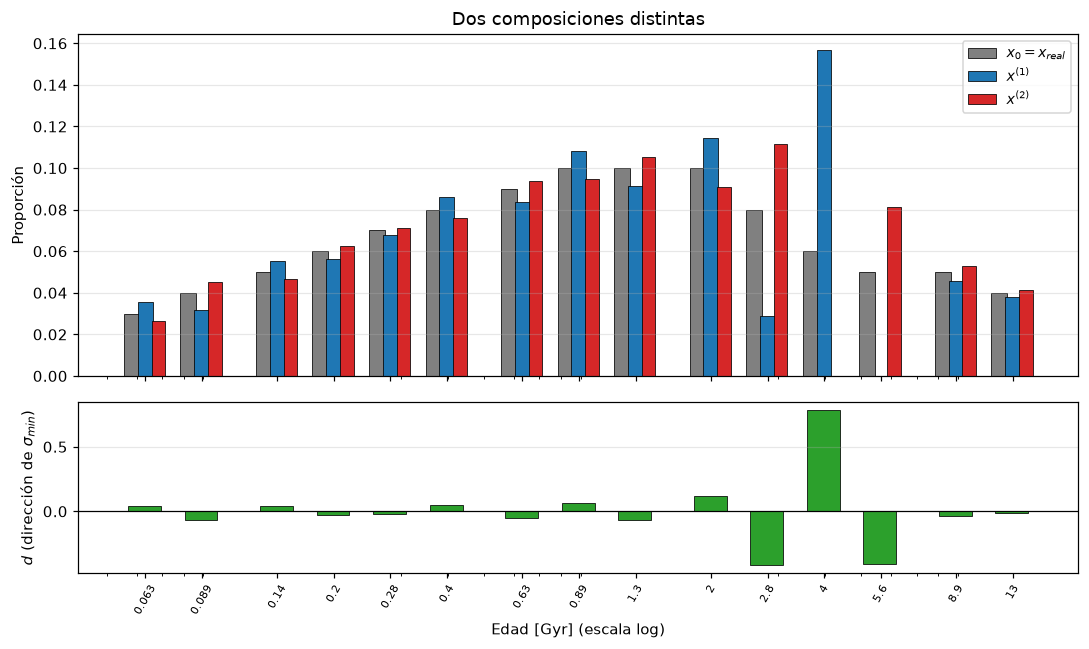

In [38]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

# Corro las barras multiplicando por 10**-0.035, 1 y 10**+0.035 porque el eje es log;
# el ancho de cada barra es proporcional a la edad para que se vea parejo en escala log
ax1.set_xscale("log")
ax1.bar(edades * 10 ** (-0.035), x_real, width=edades * 0.09, color="gray",
        edgecolor="k", linewidth=0.5, label=r"$x_0 = x_{real}$")
ax1.bar(edades, x1, width=edades * 0.09, color="C0", edgecolor="k",
        linewidth=0.5, label=r"$x^{(1)}$")
ax1.bar(edades * 10 ** (+0.035), x2, width=edades * 0.09, color="C3",
        edgecolor="k", linewidth=0.5, label=r"$x^{(2)}$")
ax1.set_ylabel("Proporción")
ax1.set_title("Dos composiciones distintas")
ax1.legend(loc="best", fontsize=9)

ax2.set_xscale("log")
ax2.bar(edades, d, width=edades * 0.2, color="C2", edgecolor="k", linewidth=0.5)
ax2.axhline(0, color="k", linewidth=0.8)
ax2.set_ylabel(r"$d$ (dirección de $\sigma_{min}$)")
ax2.set_xlabel("Edad [Gyr] (escala log)")

for ax in (ax1, ax2):
    ax.set_xticks(edades)
    ax.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=7)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(True, axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

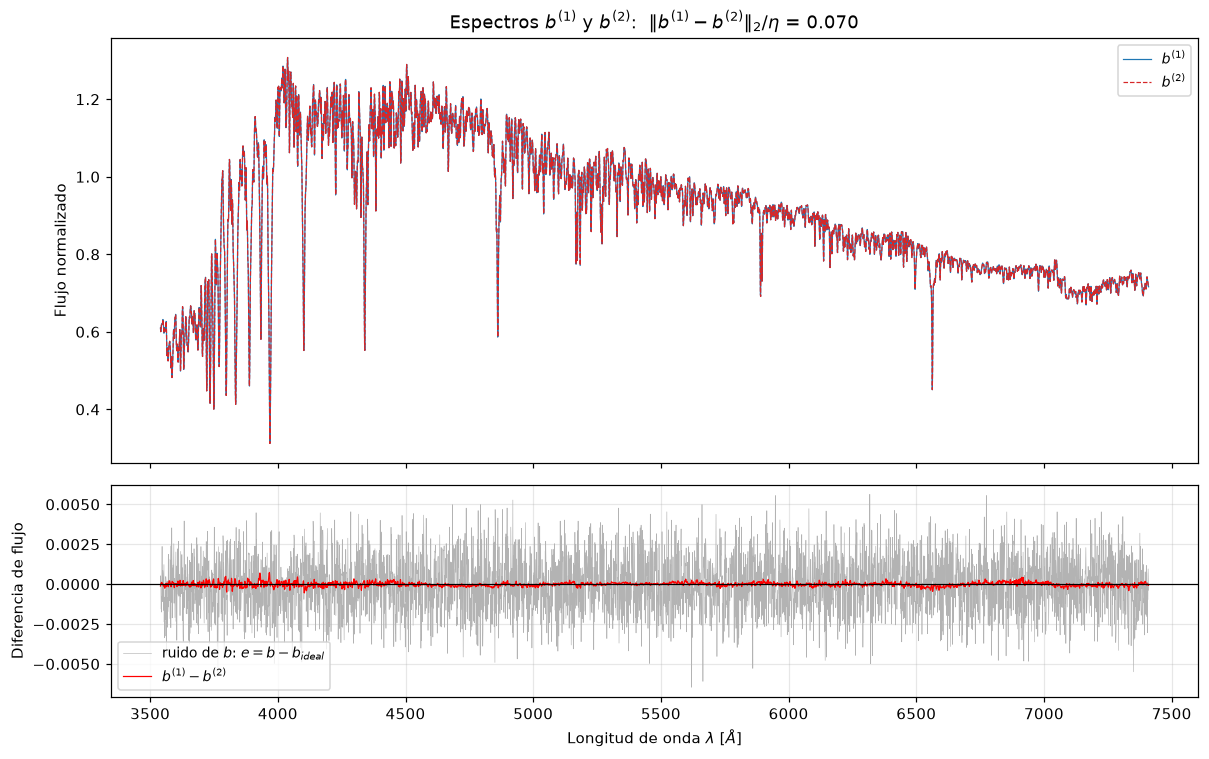

In [39]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(lam, b1, color="C0", lw=0.8, label=r"$b^{(1)}$")
ax1.plot(lam, b2, color="C3", lw=0.8, linestyle="--", label=r"$b^{(2)}$")
ax1.set_ylabel("Flujo normalizado")
ax1.set_title(rf"Espectros $b^{{(1)}}$ y $b^{{(2)}}$:  $\|b^{{(1)}}-b^{{(2)}}\|_2 / \eta$ = {ratio:.3f}")
ax1.legend(loc="best", fontsize=9)

ax2.plot(lam, e, color="0.7", lw=0.4, label=r"ruido de $b$: $e = b - b_{ideal}$")
ax2.plot(lam, db, color="red", lw=0.8, label=r"$b^{(1)} - b^{(2)}$")
ax2.axhline(0, color="k", linewidth=0.8)
ax2.set_xlabel("Longitud de onda $\\lambda$ [$\\AA$]")
ax2.set_ylabel("Diferencia de flujo")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="best", fontsize=9)

fig.tight_layout()
plt.show()

### Conclusiones del ejercicio 5

1. La QR completa de $\mathbf 1$ da una base ortonormal $Q_2$ de las redistribuciones ($\mathbf 1^\top d = 0$), y la SVD de $AQ_2$ las ordena según cuánto cambian el espectro. La menos visible tiene $\|Ad\| = \sigma_{min}(AQ_2) \approx 0{,}040$, unas 1600 veces menos que la más visible.
2. Esa redistribución es un patrón $(-1, 2, -1)$ sobre 2,8, 4 y 5,6 Gyr: el espectro de una población vieja es casi el promedio de los de sus vecinas en $\log t$.
3. Moviéndose sobre $d$ hasta el borde de $x\ge0$ se obtienen dos composiciones válidas que difieren en un 73 % (22 % de la luz reasignada) y cuyos espectros difieren en solo **0,07 $\eta$**. La restricción activa es la positividad: el ruido permitiría diferencias ~14 veces mayores.
4. **No es posible recuperar una única distribución de edades a partir de $b$ con este nivel de ruido.** Aunque $A$ tiene rango completo y la solución de cuadrados mínimos es matemáticamente única, hay todo un conjunto de composiciones físicamente válidas compatibles con los datos. Tomando cambios del tamaño de los encontrados acá ($\|\Delta x\|\approx0{,}2$), toda dirección con $\sigma_i(AQ_2) \lesssim \eta/0{,}2 \approx 0{,}57$ produce espectros indistinguibles: son 10 de las 14 redistribuciones posibles. El espectro determina con precisión solo unas pocas combinaciones (el total y la forma gruesa de la distribución, coherente con el codo en $\sigma_4$ del Ej. 3), no el aporte de cada edad por separado.
5. Por eso los métodos regularizados de los Ej. 3 y 4 no "descubren" la composición verdadera: eligen, entre todas las compatibles con los datos, la que satisface un criterio impuesto (menor norma, componentes truncadas). Su error en $x$ del ~6 % está justamente en estas direcciones no determinadas. Para afirmar algo sobre edades individuales hace falta información adicional (menos ruido, más rango espectral, o supuestos a priori como suavidad en edad), o bien reportar resultados agrupados en rangos de edad.